## Importing Libraries


In [1]:
import os
import sys
import io
import glob
import random
import copy
import gzip
import argparse
from datetime import datetime
from collections import defaultdict, Counter
import csv

import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy.stats import wasserstein_distance  # EMD calculation
from scipy.spatial.distance import jensenshannon  # JS calculation
from sklearn.cluster import KMeans

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset, Dataset, random_split

import wandb
import time
import psutil

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from tqdm import tqdm
from sklearn.metrics import silhouette_score, silhouette_samples

torch.backends.cudnn.benchmark = True

In [2]:
!nvidia-smi
!pip install zstandard

Thu Feb 12 03:50:34 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   40C    P8             13W /   72W |       0MiB /  23034MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

# **Installation packges and connect to the drive**

## Connect Google Drive

In [3]:
def detect_platform():
    if "google.colab" in sys.modules:
        return "colab"
    elif os.path.exists("/kaggle/input"):
        return "kaggle"
    else:
        return "Local or Other"

RUNNING_PLATFORM = detect_platform() # kaggle , colab
print(f"Running on {RUNNING_PLATFORM}")

if RUNNING_PLATFORM == "colab":
    from google.colab import drive
    drive.mount('/content/drive')
    CLIENTS_DATASETS_PATH = "/content/drive/MyDrive/FYP/Realworld_Distribution_C100_1/"
    HISTORY_SAVE_PATH = '/content/drive/MyDrive/Engineering-UOR/Final Year Project/Implementations/Security/JS/history/'

elif RUNNING_PLATFORM == "kaggle":
    CLIENTS_DATASETS_PATH = "/kaggle/working/"
    HISTORY_SAVE_PATH  = "/kaggle/working/history/"

     # Install the gdown library if needed (it's often pre-installed)
    !pip install gdown -q

    import gdown
    import pandas as pd

    # 1. Correctly define the File ID from your link
    file_id = '1ISB4wQdrsqE60ViM7qdKaUPtDyU88xBZ' #1ISB4wQdrsqE60ViM7qdKaUPtDyU88xBZ  1B9OyU2TMfygXszFZ6vh13qo-zSkjU6pa
    output_filename = 'client_datasets.pkl'

    # 2. Download the file using the correct URL format
    gdown.download(f'https://drive.google.com/uc?id={file_id}', output_filename, quiet=False)

    # 3. CRITICAL: Use pd.read_pickle for .pkl files
    print(f"\nSuccessfully downloaded {output_filename}. Now reading with pd.read_pickle...")
    df = pd.read_pickle(output_filename)

    print("\nFile read successfully! Here is the head of the DataFrame:")

else :
    print("select valid platform to run the code.")

Running on colab
Mounted at /content/drive


# Parameter


In [4]:
# Parameters
FL_ROUNDS: int = 300
LOCAL_EPOCHS: int = 6
NUM_CLIENTS: int = 100
BATCH_SIZE: int = 64
NUM_SELECTED_CLIENTS: int = 10
SECURITY :str = "ON" # OFF ON
FL_ALGO:str = "JS"

MAX_CLIENTS_POOL_SIZE = 10
MAX_USED_TERMS = 2 * NUM_SELECTED_CLIENTS
IID_MEASURE_METHOD = "JS"  # "CAFA" # "JS-ClientDatasetSize" , "JS" or  None


# Experiment Parameters



EXPERIMENT_NAME: str = "(1-JSD)_C100" #JS, JS-ClientDatasetSize, FedAvg, AccuracyBased-JS, ""AccuracyBased_(1-JS)_new_performance_quantization""
MODEL_NAME: str = "VGG19"
DATASET_DISTRIBUTION_TYPE: str = "RealWorld_Dataset_Distribution_C100" # "Realworld_Distribution_C20_1"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# HISTORY_FOLDER_NAME = f'EX-{EXPERIMENT_NAME}_MODEL-{MODEL_NAME}_FLROUND-{FL_ROUNDS}_NUMCLI-{NUM_CLIENTS}_CLILOCALEPOCH-{LOCAL_EPOCHS}_DST{DATASET_DISTRIBUTION_TYPE}'
# HISTORY_DIR = os.path.join(HISTORY_SAVE_PATH, HISTORY_FOLDER_NAME)

# Quantization Parameters (existing)
ENABLE_QUANTIZATION: bool = True  # Enable/disable quantization
QUANTIZATION_BITS: int = 8  # Number of bits for quantization (8 for INT8)
QUANTIZATION_METHOD: str = "uniform"  # uniform, dynamic (for future extensions)

# Model Pruning Parameters
ENABLE_PRUNING: bool = True  # Enable/disable model pruning
PRUNING_SPARSITY: float = 0.3  # Target sparsity (30% of weights pruned)
PRUNING_METHOD: str = "magnitude"  # magnitude, random, structured
PRUNING_SCHEDULE: str = "gradual"  # gradual, oneshot
PRUNING_START_ROUND: int = 20  # Start pruning after this round
PRUNING_END_ROUND: int = 80  # Complete pruning by this round

# Early Stopping Parameters
ENABLE_EARLY_STOPPING: bool = False  # Enable/disable early stopping
EARLY_STOPPING_PATIENCE: int = 10  # Rounds to wait for improvement
EARLY_STOPPING_MIN_DELTA: float = 0.001  # Minimum improvement threshold
EARLY_STOPPING_METRIC: str = "accuracy"  # accuracy, loss
EARLY_STOPPING_MODE: str = "max"  # max for accuracy, min for loss

# Mixed Precision Parameters
ENABLE_MIXED_PRECISION: bool = True  # Enable/disable mixed precision training
MIXED_PRECISION_LOSS_SCALE: float = 2**16  # Loss scaling factor
MIXED_PRECISION_GROWTH_FACTOR: float = 2.0  # Growth factor for loss scaling
MIXED_PRECISION_BACKOFF_FACTOR: float = 0.5  # Backoff factor for loss scaling
MIXED_PRECISION_GROWTH_INTERVAL: int = 2000  # Steps between loss scale updates

# Generate experiment name based on enabled optimizations
optimization_methods = []
if ENABLE_QUANTIZATION:
    optimization_methods.append("Quant")
if ENABLE_PRUNING:
    optimization_methods.append("Prune")
if ENABLE_EARLY_STOPPING:
    optimization_methods.append("EarlyStop")
if ENABLE_MIXED_PRECISION:
    optimization_methods.append("MixedPrec")
HISTORY_SAVE_PATH = '/content/drive/MyDrive/Final_Implementations/history/C100'
HISTORY_FOLDER_NAME = f'EX-{EXPERIMENT_NAME}_MODEL-{MODEL_NAME}_FLROUND-{FL_ROUNDS}_NUMCLI-{NUM_CLIENTS}_CLILOCALEPOCH-{LOCAL_EPOCHS}_DST{DATASET_DISTRIBUTION_TYPE}'
HISTORY_DIR = os.path.join(HISTORY_SAVE_PATH, HISTORY_FOLDER_NAME)

# **Security setup**

### save crypto metrics in CSV

In [5]:
def save_crypto_metrics_to_csv(client_timing_metrics, client_key_size_metrics, server_timing_metrics, server_key_size_metrics, round_number, base_dir="/content/crypto_metrics"):
    """
    Saves cryptographic timing and key size metrics for a given round to CSV files.

    Args:
        client_timing_metrics (list): List of dictionaries containing client timing metrics.
        client_key_size_metrics (list): List of dictionaries containing client key size metrics.
        server_timing_metrics (dict): Dictionary containing server timing metrics.
        server_key_size_metrics (dict): Dictionary containing server key size metrics.
        round_number (int): The current federated learning round number.
        base_dir (str): The base directory to save the CSV files.
    """

    os.makedirs(base_dir, exist_ok=True)

    # Define file paths
    client_timing_csv = os.path.join(base_dir, "client_timing_metrics.csv")
    client_key_size_csv = os.path.join(base_dir, "client_key_size_metrics.csv")
    server_timing_csv = os.path.join(base_dir, "server_timing_metrics.csv")
    server_key_size_csv = os.path.join(base_dir, "server_key_size_metrics.csv")

    # Helper function to write to CSV
    def write_to_csv(filepath, data, fieldnames):
        file_exists = os.path.isfile(filepath)
        with open(filepath, mode="a", newline="") as csvfile:
            writer = csv.DictWriter(csvfile, fieldnames=fieldnames)
            if not file_exists:
                writer.writeheader()
            if isinstance(data, list):
                writer.writerows(data)
            elif isinstance(data, dict):
                writer.writerow(data)

    # Save Client Timing Metrics
    if client_timing_metrics:
        client_timing_fieldnames = list(client_timing_metrics[0].keys()) if client_timing_metrics else []
        write_to_csv(client_timing_csv, client_timing_metrics, client_timing_fieldnames)

    # Save Client Key Size Metrics
    if client_key_size_metrics:
        client_key_size_fieldnames = list(client_key_size_metrics[0].keys()) if client_key_size_metrics else []
        write_to_csv(client_key_size_csv, client_key_size_metrics, client_key_size_fieldnames)

    # Save Server Timing Metrics
    if server_timing_metrics:
        server_timing_fieldnames = list(server_timing_metrics.keys())
        write_to_csv(server_timing_csv, server_timing_metrics, server_timing_fieldnames)

    # Save Server Key Size Metrics
    if server_key_size_metrics:
        server_key_size_fieldnames = list(server_key_size_metrics.keys())
        write_to_csv(server_key_size_csv, server_key_size_metrics, server_key_size_fieldnames)

    print(f"Crypto metrics for round {round_number} saved to {base_dir}")


## ML-DSA-44, ML-KEM-768, Falcon 512 Instalation





In [6]:
# Install dependencies
!apt-get update -y
!apt-get install -y cmake ninja-build gcc g++ make git python3-dev libssl-dev

# Clone liboqs and build
!git clone https://github.com/open-quantum-safe/liboqs.git
!cd liboqs && mkdir build && cd build && cmake -GNinja .. && ninja && ninja install

# Install Python bindings (pointing to the compiled liboqs)
!pip install git+https://github.com/open-quantum-safe/liboqs-python


Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Get:2 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  InRelease [1,581 B]
Get:3 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ InRelease [3,632 B]
Get:4 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  Packages [2,361 kB]
Get:5 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ Packages [85.0 kB]
Hit:6 http://archive.ubuntu.com/ubuntu jammy InRelease
Get:7 http://security.ubuntu.com/ubuntu jammy-security InRelease [129 kB]
Get:8 http://archive.ubuntu.com/ubuntu jammy-updates InRelease [128 kB]
Hit:9 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu jammy InRelease
Hit:10 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu jammy InRelease
Hit:11 https://ppa.launchpadcontent.net/ubuntugis/ppa/ubuntu jammy InRelease
Get:12 http://archive.ubuntu.com/ubuntu jammy-backports InRelease [127 kB]
Get:13 https://r2u.stat.illinois.edu/ubuntu jamm

In [7]:
import oqs

# list signature mechanisms
sig_algs = oqs.get_enabled_sig_mechanisms()

print("Available signature algorithms:")
for alg in sig_algs:
    print("-", alg)

# check for ML-DSA-44
assert "ML-DSA-44" in sig_algs, "ML-DSA-44 not available"

liboqs-python faulthandler is disabled


INFO:oqs.oqs:liboqs-python faulthandler is disabled


liboqs not found, installing it in /root/_oqs


INFO:oqs.oqs:liboqs not found, installing it in /root/_oqs


Installing in 5 seconds...


...

Installing in 1 seconds...


INFO:oqs.oqs:Installing in 1 seconds...


Done installing liboqs


INFO:oqs.oqs:Done installing liboqs


Available signature algorithms:
- Dilithium2
- Dilithium3
- Dilithium5
- ML-DSA-44
- ML-DSA-65
- ML-DSA-87
- Falcon-512
- Falcon-1024
- Falcon-padded-512
- Falcon-padded-1024
- SPHINCS+-SHA2-128f-simple
- SPHINCS+-SHA2-128s-simple
- SPHINCS+-SHA2-192f-simple
- SPHINCS+-SHA2-192s-simple
- SPHINCS+-SHA2-256f-simple
- SPHINCS+-SHA2-256s-simple
- SPHINCS+-SHAKE-128f-simple
- SPHINCS+-SHAKE-128s-simple
- SPHINCS+-SHAKE-192f-simple
- SPHINCS+-SHAKE-192s-simple
- SPHINCS+-SHAKE-256f-simple
- SPHINCS+-SHAKE-256s-simple
- MAYO-1
- MAYO-2
- MAYO-3
- MAYO-5
- cross-rsdp-128-balanced
- cross-rsdp-128-fast
- cross-rsdp-128-small
- cross-rsdp-192-balanced
- cross-rsdp-192-fast
- cross-rsdp-192-small
- cross-rsdp-256-balanced
- cross-rsdp-256-fast
- cross-rsdp-256-small
- cross-rsdpg-128-balanced
- cross-rsdpg-128-fast
- cross-rsdpg-128-small
- cross-rsdpg-192-balanced
- cross-rsdpg-192-fast
- cross-rsdpg-192-small
- cross-rsdpg-256-balanced
- cross-rsdpg-256-fast
- cross-rsdpg-256-small
- OV-Is
- OV

## Rudraksh

### New Ipml

In [8]:
# Install JPype to bridge Python and Java
!pip install JPype1

# Clone your repository
!git clone https://github.com/SalindaGunarathna/RudrakshKEM.git
%cd RudrakshKEM

# Install Maven in Colab
!apt-get update
!apt-get install -y maven

# Build your Maven project
!mvn clean package -DskipTests

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 495.9/495.9 kB 40.9 MB/s eta 0:00:00
Cloning into 'RudrakshKEM'...
remote: Enumerating objects: 60, done.
remote: Counting objects: 100% (60/60), done.
remote: Compressing objects: 100% (34/34), done.
remote: Total 60 (delta 6), reused 60 (delta 6), pack-reused 0 (from 0)
Receiving objects: 100% (60/60), 16.03 KiB | 8.02 MiB/s, done.
Resolving deltas: 100% (6/6), done.
/content/RudrakshKEM
Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Hit:2 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  InRelease
Hit:3 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ InRelease
Hit:4 http://security.ubuntu.com/ubuntu jammy-security InRelease
Hit:5 http://archive.ubuntu.com/ubuntu jammy InRelease
Hit:6 http://archive.ubuntu.com/ubuntu jammy-updates InRelease
Hit:7 http://archive.ubuntu.com/ubuntu jammy-backports InRelease
Hit:8 https://r2u.stat.illinois.edu/ubuntu jammy InRelease
Hit:9 https://ppa.launch

In [9]:
import jpype
import jpype.imports
import glob
import os

# Navigate to project
%cd /content/RudrakshKEM

# Get all dependencies
print("📦 Copying dependencies...")
!mvn dependency:copy-dependencies -DoutputDirectory=target/dependencies -q

# Shutdown JVM if running
if jpype.isJVMStarted():
    jpype.shutdownJVM()
    print("✓ JVM shut down")

# Collect all JARs
main_jar = "./target/security-protocole-1.0-SNAPSHOT.jar"
dep_jars = glob.glob("./target/dependencies/*.jar")
all_jars = [main_jar] + dep_jars

print(f"✓ Found {len(all_jars)} JARs")
for jar in all_jars[:5]:
    print(f"  - {os.path.basename(jar)}")
if len(all_jars) > 5:
    print(f"  ... and {len(all_jars) - 5} more")

# Start JVM with all dependencies
jpype.startJVM(classpath=all_jars)
print("✓ JVM started with all dependencies\n")

# Now run your code
from org.security.rudraksh import RudrakshKEM

kem = RudrakshKEM()
print("✓ RudrakshKEM instance created")

pk = RudrakshKEM.KEMPk()
sk = RudrakshKEM.KEMSk()

print("\n1. Generating KEM key pair...")
kem.kemKeyGen(pk, sk)
print("✓ Key pair generated")

print("\n2. Performing encapsulation...")
result = kem.kemEncaps(pk)
ciphertext = result[0]
shared_secret_enc = result[1]
print(f"✓ Ciphertext size: {len(ciphertext)} bytes")
print(f"✓ Shared secret size: {len(shared_secret_enc)} bytes")

print("\n3. Performing decapsulation...")
shared_secret_dec = kem.kemDecaps(pk, sk, ciphertext)
print("✓ Decapsulation complete")

import array
if array.array('b', shared_secret_enc) == array.array('b', shared_secret_dec):
    print("\n✅ SUCCESS: Shared secrets match!")
else:
    print("\n❌ FAILURE: Shared secrets don't match!")

/content/RudrakshKEM
📦 Copying dependencies...
✓ Found 6 JARs
  - security-protocole-1.0-SNAPSHOT.jar
  - bcpkix-jdk18on-1.81.jar
  - bcprov-jdk18on-1.81.jar
  - bcutil-jdk18on-1.81.jar
  - junit-4.13.2.jar
  ... and 1 more
✓ JVM started with all dependencies

✓ RudrakshKEM instance created

1. Generating KEM key pair...
✓ Key pair generated

2. Performing encapsulation...
✓ Ciphertext size: 1280 bytes
✓ Shared secret size: 16 bytes

3. Performing decapsulation...
✓ Decapsulation complete

✅ SUCCESS: Shared secrets match!


## **Ascon C installation**

In [10]:
!git clone https://github.com/rweather/ascon-suite.git

Cloning into 'ascon-suite'...
remote: Enumerating objects: 5466, done.
remote: Counting objects: 100% (757/757), done.
remote: Compressing objects: 100% (310/310), done.
remote: Total 5466 (delta 485), reused 664 (delta 443), pack-reused 4709 (from 1)
Receiving objects: 100% (5466/5466), 6.19 MiB | 11.98 MiB/s, done.
Resolving deltas: 100% (4459/4459), done.


In [11]:
!mkdir ascon-suite/build
!cd ascon-suite/build && cmake ..
!cd ascon-suite/build && make
!cd ascon-suite/build && make install

CMake Deprecation Warning at CMakeLists.txt:1 (cmake_minimum_required):
  Compatibility with CMake < 3.10 will be removed from a future version of
  CMake.

  Update the VERSION argument <min> value.  Or, use the <min>...<max> syntax
  to tell CMake that the project requires at least <min> but has been updated
  to work with policies introduced by <max> or earlier.


-- The C compiler identification is GNU 11.4.0
-- The CXX compiler identification is GNU 11.4.0
-- The ASM compiler identification is GNU
-- Found assembler: /usr/bin/cc
-- Detecting C compiler ABI info
-- Detecting C compiler ABI info - done
-- Check for working C compiler: /usr/bin/cc - skipped
-- Detecting C compile features
-- Detecting C compile features - done
-- Detecting CXX compiler ABI info
-- Detecting CXX compiler ABI info - done
-- Check for working CXX compiler: /usr/bin/c++ - skipped
-- Detecting CXX compile features
-- Detecting CXX compile features - done
-- Performing Test HAVE_THREAD_KEYWORD
-- Performin

In [12]:
# ascon_aead_wrapper.py

import ctypes

AEAD_VARIANTS = {
    'ascon128': {'key_len': 16, 'nonce_len': 16},
    'ascon128a': {'key_len': 16, 'nonce_len': 16},
    'ascon80pq': {'key_len': 20, 'nonce_len': 16},
}

class AsconAEAD:
    def __init__(self, variant: str = 'ascon128a'):
        if variant not in AEAD_VARIANTS:
            raise ValueError(f"Unsupported variant: {variant}")

        self.variant = variant
        self.key_len = AEAD_VARIANTS[variant]['key_len']
        self.nonce_len = AEAD_VARIANTS[variant]['nonce_len']

        self.lib = ctypes.CDLL('./ascon-suite/build/src/libascon.so')

        # Get function pointers dynamically
        try:
            self.encrypt = getattr(self.lib, f"{variant}_aead_encrypt")
            self.decrypt = getattr(self.lib, f"{variant}_aead_decrypt")
        except AttributeError:
            raise RuntimeError(f"Encryption/decryption functions for {variant} not found in the library")

        self.encrypt.argtypes = [
            ctypes.POINTER(ctypes.c_ubyte), ctypes.POINTER(ctypes.c_size_t),
            ctypes.POINTER(ctypes.c_ubyte), ctypes.c_size_t,
            ctypes.POINTER(ctypes.c_ubyte), ctypes.c_size_t,
            ctypes.POINTER(ctypes.c_ubyte),
            ctypes.POINTER(ctypes.c_ubyte)
        ]
        self.decrypt.argtypes = self.encrypt.argtypes
        self.decrypt.restype = ctypes.c_int

    def encrypt_data(self, plaintext: bytes, ad: bytes, nonce: bytes, key: bytes):
        if len(key) != self.key_len or len(nonce) != self.nonce_len:
            raise ValueError("Invalid key or nonce length for variant")

        pt_len = len(plaintext)
        ct_buf = (ctypes.c_ubyte * (pt_len + 16))()
        ct_len = ctypes.c_size_t(0)

        pt_buf = (ctypes.c_ubyte * pt_len)(*plaintext)
        ad_buf = (ctypes.c_ubyte * len(ad))(*ad)
        nonce_buf = (ctypes.c_ubyte * len(nonce))(*nonce)
        key_buf = (ctypes.c_ubyte * len(key))(*key)

        self.encrypt(ct_buf, ctypes.byref(ct_len), pt_buf, pt_len, ad_buf, len(ad), nonce_buf, key_buf)
        return bytes(ct_buf[:ct_len.value])

    def decrypt_data(self, ciphertext: bytes, ad: bytes, nonce: bytes, key: bytes):
        if len(key) != self.key_len or len(nonce) != self.nonce_len:
            raise ValueError("Invalid key or nonce length for variant")

        ct_len = len(ciphertext)
        pt_buf = (ctypes.c_ubyte * ct_len)()
        pt_len = ctypes.c_size_t(0)

        ct_buf = (ctypes.c_ubyte * ct_len)(*ciphertext)
        ad_buf = (ctypes.c_ubyte * len(ad))(*ad)
        nonce_buf = (ctypes.c_ubyte * len(nonce))(*nonce)
        key_buf = (ctypes.c_ubyte * len(key))(*key)

        result = self.decrypt(pt_buf, ctypes.byref(pt_len), ct_buf, ct_len, ad_buf, len(ad), nonce_buf, key_buf)
        if result == 0:
            return bytes(pt_buf[:pt_len.value])
        else:
            raise ValueError("Decryption failed: Invalid tag or input")

In [13]:
encr_algo = "ascon80pq" # or ascon128, ascon80pq
ascon_aead =  AsconAEAD(variant=encr_algo)
key = b'\x00' * 20
nonce = b'\x00' * 16
ad = b'example-ad'
plaintext = b'Hello Ascon!'

ciphertext = ascon_aead.encrypt_data(plaintext, ad, nonce, key)
print("Ciphertext:", ciphertext)

decrypted = ascon_aead.decrypt_data(ciphertext, ad, nonce, key)
print("Decrypted:", decrypted)


Ciphertext: b'1|Sl\xc4\x18\xd3q\x05\x12\x16\xd0\xd7\x05\xee\x92]\x99\x06\x1c\xf1\xb4y\xc8\xd8(\x1ej'
Decrypted: b'Hello Ascon!'


## Optimization - Step 1: Helper Functions

In [14]:

# === Performance Metrics Utilities (ADDED) ===
# Do not modify existing structures. These helpers collect computational and communication metrics,
# log locally and to Weights & Biases (wandb). They are safe to keep alongside existing code.

import psutil, io, time, json, math
try:
    import pynvml
    pynvml_available = True
    pynvml.nvmlInit()
except Exception:
    pynvml_available = False

# Communication & computational metric lists (global)
comm_bytes_sent_list = []
comm_serialize_time_list = []
model_size_bytes_list = []
local_client_start_end_times = []  # (client_id, start, end)
system_usage_snapshots = []  # list of dicts per measurement

# WandB init helper (only initialize once)
def init_wandb_if_needed(project_name="FL-Metrics", run_name=None, config=None):
    try:
        if 'wandb' in globals() and wandb.run is not None:
            return
    except Exception:
        pass
    try:
        import wandb
        wandb.init(project=project_name, name=run_name, config=config, reinit=True)
        print("wandb initialized.")
    except Exception as e:
        print("wandb init failed:", e)

def get_system_usage_snapshot():
    usage = {}
    # CPU, RAM
    usage['cpu_percent'] = psutil.cpu_percent(interval=None)
    usage['memory_percent'] = psutil.virtual_memory().percent
    usage['memory_used_mb'] = psutil.virtual_memory().used / 1e6
    # GPU (if available)
    try:
        import torch
        if torch.cuda.is_available():
            if pynvml_available:
                handle = pynvml.nvmlDeviceGetHandleByIndex(0)
                info = pynvml.nvmlDeviceGetMemoryInfo(handle)
                usage['gpu_mem_total_mb'] = info.total / 1e6
                usage['gpu_mem_used_mb'] = info.used / 1e6
                usage['gpu_util_percent'] = pynvml.nvmlDeviceGetUtilizationRates(handle).gpu
            else:
                usage['gpu_mem_allocated_mb'] = torch.cuda.memory_allocated(0) / 1e6
                try:
                    usage['gpu_util_percent'] = torch.cuda.utilization(0)
                except Exception:
                    pass
    except Exception:
        pass
    return usage

def get_model_size_bytes(model):
    """Serialize state_dict to buffer and return size in bytes"""
    try:
        import torch, io
        buffer = io.BytesIO()
        torch.save(model.state_dict(), buffer)
        size = buffer.getbuffer().nbytes
        return size
    except Exception as e:
        # fallback: estimate by summing parameter element sizes
        total = 0
        try:
            for p in model.parameters():
                total += p.numel() * p.element_size()
            return total
        except Exception:
            return 0

def log_metrics_locally_and_wandb(step=None, extra=None):
    # Logs the current aggregated metrics to wandb (if available) and prints a short summary
    summary = {
        "comm_bytes_sent_mean": sum(comm_bytes_sent_list)/len(comm_bytes_sent_list) if comm_bytes_sent_list else 0,
        "model_size_bytes_mean": sum(model_size_bytes_list)/len(model_size_bytes_list) if model_size_bytes_list else 0,
        "serialize_time_mean": sum(comm_serialize_time_list)/len(comm_serialize_time_list) if comm_serialize_time_list else 0,
    }
    if extra:
        summary.update(extra)
    # try wandb
    try:
        import wandb
        if wandb.run is not None:
            wandb.log(summary, step=step)
    except Exception:
        pass
    # also print concise summary
    print(f"[METRICS] step={step} comm_mean={summary['comm_bytes_sent_mean']:.1f} bytes model_mean={summary['model_size_bytes_mean']:.1f} bytes ser_time_mean={summary['serialize_time_mean']:.4f}s")


### QUANTIZATION INTEGRATION

In [15]:
# ============================================================
# QUANTIZATION HELPER FUNCTIONS
# ============================================================

def quantize_model_parameters(state_dict, num_bits=8):
    """
    Quantize model parameters to reduce communication overhead.
    This simulates INT8 quantization for model weights.

    Args:
        state_dict: Model state dictionary
        num_bits: Number of bits for quantization (default: 8 for INT8)

    Returns:
        quantized_dict: Dictionary with quantized parameters
        metadata: Quantization metadata (scales, zero_points) for dequantization
    """
    quantized_dict = {}
    metadata = {}

    for key, param in state_dict.items():
        if param.dtype == torch.float32 or param.dtype == torch.float16:
            # Calculate scale and zero point for quantization
            param_np = param.cpu().numpy()
            min_val = param_np.min()
            max_val = param_np.max()

            # Calculate quantization parameters
            qmin = 0
            qmax = 2**num_bits - 1

            scale = (max_val - min_val) / (qmax - qmin) if max_val != min_val else 1.0
            zero_point = qmin - min_val / scale if scale != 0 else 0

            # Quantize
            quantized = np.round(param_np / scale + zero_point)
            quantized = np.clip(quantized, qmin, qmax).astype(np.uint8)

            # Store quantized values and metadata
            quantized_dict[key] = quantized
            metadata[key] = {'scale': scale, 'zero_point': zero_point, 'shape': param.shape, 'dtype': param.dtype}
        else:
            # For non-float parameters, keep as is
            quantized_dict[key] = param.cpu().numpy()
            metadata[key] = {'quantized': False, 'shape': param.shape, 'dtype': param.dtype}

    return quantized_dict, metadata


def dequantize_model_parameters(quantized_dict, metadata, device):
    """
    Dequantize model parameters back to float32.

    Args:
        quantized_dict: Dictionary with quantized parameters
        metadata: Quantization metadata
        device: Device to load parameters to

    Returns:
        state_dict: Dequantized state dictionary
    """
    state_dict = {}

    for key, quantized_param in quantized_dict.items():
        meta = metadata[key]

        if 'scale' in meta:  # This parameter was quantized
            scale = meta['scale']
            zero_point = meta['zero_point']

            # Dequantize
            dequantized = (quantized_param.astype(np.float32) - zero_point) * scale
            state_dict[key] = torch.tensor(dequantized, dtype=meta['dtype']).to(device)
        else:
            # This parameter was not quantized
            state_dict[key] = torch.tensor(quantized_param, dtype=meta['dtype']).to(device)

    return state_dict


def calculate_size_reduction(original_state_dict, quantized_dict):
    """
    Calculate the size reduction achieved by quantization.

    Args:
        original_state_dict: Original float32 state dict
        quantized_dict: Quantized state dict

    Returns:
        original_size_MB: Original size in MB
        quantized_size_MB: Quantized size in MB
        reduction_percent: Reduction percentage
    """
    # Calculate original size
    original_size = 0
    for param in original_state_dict.values():
        original_size += param.element_size() * param.nelement()

    # Calculate quantized size
    quantized_size = 0
    for param in quantized_dict.values():
        if isinstance(param, np.ndarray):
            quantized_size += param.nbytes
        else:
            quantized_size += param.element_size() * param.nelement()

    original_size_MB = original_size / (1024 * 1024)
    quantized_size_MB = quantized_size / (1024 * 1024)
    reduction_percent = ((original_size_MB - quantized_size_MB) / original_size_MB) * 100

    return original_size_MB, quantized_size_MB, reduction_percent


def serialize_quantized_model(quantized_dict, metadata):
    """
    Serialize quantized model for transmission.
    This simulates the actual bytes that would be sent over the network.

    Returns:
        Serialized bytes object
    """
    import io
    buffer = io.BytesIO()
    pickle.dump({'quantized': quantized_dict, 'metadata': metadata}, buffer)
    return buffer.getvalue()


def deserialize_quantized_model(serialized_data):
    """
    Deserialize quantized model received from network.

    Returns:
        quantized_dict, metadata
    """
    import io
    buffer = io.BytesIO(serialized_data)
    data = pickle.load(buffer)
    return data['quantized'], data['metadata']


print(" Quantization helper functions loaded successfully!")


 Quantization helper functions loaded successfully!


### MODEL PRUNING FUNCTIONS

In [16]:
# ============================================================
# 🔹 MODEL PRUNING FUNCTIONS
# ============================================================

import torch.nn.utils.prune as prune
from torch.cuda.amp import GradScaler, autocast

class ModelPruner:
    """Handles model pruning operations for federated learning."""

    def __init__(self):
        self.pruning_history = []
        self.sparsity_history = []
        self.pruned_modules = {}

    def calculate_sparsity(self, model):
        """Calculate current sparsity of the model."""
        total_params = 0
        zero_params = 0

        for module in model.modules():
            if isinstance(module, (nn.Conv2d, nn.Linear)):
                if hasattr(module, 'weight_mask'):
                    # Pruned module
                    mask = module.weight_mask
                    total_params += mask.numel()
                    zero_params += (mask == 0).sum().item()
                else:
                    # Unpruned module
                    weight = module.weight
                    total_params += weight.numel()
                    zero_params += (weight == 0).sum().item()

        sparsity = zero_params / total_params if total_params > 0 else 0
        return sparsity

    def apply_magnitude_pruning(self, model, sparsity):
        """Apply magnitude-based pruning to the model."""
        modules_to_prune = []

        for name, module in model.named_modules():
            if isinstance(module, (nn.Conv2d, nn.Linear)):
                modules_to_prune.append((module, 'weight'))

        if modules_to_prune:
            prune.global_unstructured(
                modules_to_prune,
                pruning_method=prune.L1Unstructured,
                amount=sparsity,
            )

        return model

    def apply_structured_pruning(self, model, sparsity):
        """Apply structured pruning (channel-wise) to the model."""
        for name, module in model.named_modules():
            if isinstance(module, nn.Conv2d):
                # Prune entire channels
                prune.ln_structured(
                    module,
                    name='weight',
                    amount=sparsity,
                    n=2,
                    dim=0  # Prune output channels
                )
            elif isinstance(module, nn.Linear):
                # Prune neurons
                prune.ln_structured(
                    module,
                    name='weight',
                    amount=sparsity,
                    n=2,
                    dim=0  # Prune output neurons
                )

        return model

    def apply_random_pruning(self, model, sparsity):
        """Apply random pruning to the model."""
        modules_to_prune = []

        for name, module in model.named_modules():
            if isinstance(module, (nn.Conv2d, nn.Linear)):
                modules_to_prune.append((module, 'weight'))

        if modules_to_prune:
            prune.global_unstructured(
                modules_to_prune,
                pruning_method=prune.RandomUnstructured,
                amount=sparsity,
            )

        return model

    def prune_model(self, model, target_sparsity, method="magnitude"):
        """Apply pruning to the model based on the specified method."""
        if not ENABLE_PRUNING:
            return model, 0

        start_time = time.time()

        if method == "magnitude":
            model = self.apply_magnitude_pruning(model, target_sparsity)
        elif method == "structured":
            model = self.apply_structured_pruning(model, target_sparsity)
        elif method == "random":
            model = self.apply_random_pruning(model, target_sparsity)
        else:
            raise ValueError(f"Unknown pruning method: {method}")

        pruning_time = time.time() - start_time
        actual_sparsity = self.calculate_sparsity(model)

        self.pruning_history.append({
            'method': method,
            'target_sparsity': target_sparsity,
            'actual_sparsity': actual_sparsity,
            'pruning_time': pruning_time
        })

        return model, actual_sparsity

    def remove_pruning_masks(self, state_dict):
        """
        Remove pruning masks and related keys from a state dictionary,
        applying the mask to the pruned parameter values under their original names.
        """
        cleaned_state_dict = {}
        mask_keys = [k for k in state_dict if k.endswith('_mask')]

        for mask_key in mask_keys:
            orig_key = mask_key.replace('_mask', '_orig')
            weight_key = mask_key.replace('_mask', '')
            if orig_key in state_dict:
                # Apply the mask to get the pruned weight
                masked_weight = state_dict[orig_key] * state_dict[mask_key]
                cleaned_state_dict[weight_key] = masked_weight

        # Add remaining non-pruning keys
        for key, value in state_dict.items():
            if not key.endswith('_orig') and not key.endswith('_mask'):
                if key not in cleaned_state_dict:  # Avoid overwriting if already set
                    cleaned_state_dict[key] = value

        return cleaned_state_dict


    def get_pruning_summary(self):
        """Get summary of pruning operations."""
        if not self.pruning_history:
            return {}

        return {
            'total_pruning_operations': len(self.pruning_history),
            'avg_pruning_time': np.mean([h['pruning_time'] for h in self.pruning_history]),
            'final_sparsity': self.pruning_history[-1]['actual_sparsity'] if self.pruning_history else 0,
            'total_pruning_time': sum([h['pruning_time'] for h in self.pruning_history])
        }


### EARLY STOPPING FUNCTIONS

In [17]:


# ============================================================
# 🔹 EARLY STOPPING FUNCTIONS
# ============================================================

class EarlyStopping:
    """Early stopping handler for federated learning."""

    def __init__(self, patience=10, min_delta=0.001, metric="accuracy", mode="max"):
        self.patience = patience
        self.min_delta = min_delta
        self.metric = metric
        self.mode = mode
        self.best_score = None
        self.counter = 0
        self.early_stop = False
        self.history = []

    def __call__(self, score, round_num):
        """Check if early stopping criteria is met."""
        if not ENABLE_EARLY_STOPPING:
            return False

        self.history.append({'round': round_num, 'score': score})

        if self.best_score is None:
            self.best_score = score
        elif self._is_improvement(score):
            self.best_score = score
            self.counter = 0
        else:
            self.counter += 1

        if self.counter >= self.patience:
            self.early_stop = True
            print(f"\n🛑 Early stopping triggered at round {round_num + 1}")
            print(f"   No improvement in {self.metric} for {self.patience} rounds")
            print(f"   Best {self.metric}: {self.best_score:.4f}")

        return self.early_stop

    def _is_improvement(self, score):
        """Check if the score is an improvement."""
        if self.mode == "max":
            return score > self.best_score + self.min_delta
        else:
            return score < self.best_score - self.min_delta

    def get_summary(self):
        """Get early stopping summary."""
        return {
            'early_stopped': self.early_stop,
            'best_score': self.best_score,
            'patience_counter': self.counter,
            'total_rounds_monitored': len(self.history)
        }



### MIXED PRECISION TRAINING FUNCTIONS

In [18]:

# ============================================================
# 🔹 MIXED PRECISION TRAINING FUNCTIONS
# ============================================================

class MixedPrecisionTrainer:
    """Handles mixed precision training for federated learning."""

    def __init__(self):
        self.scaler = GradScaler() if ENABLE_MIXED_PRECISION and torch.cuda.is_available() else None
        self.mixed_precision_history = []

    def train_with_mixed_precision(self, model, dataloader, optimizer, criterion, epochs, device):
        """Train model with mixed precision if enabled."""
        if not ENABLE_MIXED_PRECISION or not torch.cuda.is_available():
            return self._train_regular(model, dataloader, optimizer, criterion, epochs, device)

        model.train()
        total_loss = 0.0
        correct = 0
        total = 0

        for epoch in range(epochs):
            epoch_loss = 0.0
            epoch_correct = 0
            epoch_total = 0

            for inputs, labels in dataloader:
                inputs, labels = inputs.to(device), labels.to(device)

                optimizer.zero_grad()

                # Forward pass with autocast
                with autocast():
                    outputs = model(inputs)
                    loss = criterion(outputs, labels)

                # Backward pass with gradient scaling
                self.scaler.scale(loss).backward()
                self.scaler.step(optimizer)
                self.scaler.update()

                # Statistics
                epoch_loss += loss.item() * inputs.size(0)
                _, predicted = torch.max(outputs, 1)
                epoch_correct += (predicted == labels).sum().item()
                epoch_total += labels.size(0)

            total_loss += epoch_loss
            correct += epoch_correct
            total += labels.size(0)

            avg_loss = epoch_loss / epoch_total
            accuracy = 100. * epoch_correct / epoch_total

        # Record mixed precision statistics
        self.mixed_precision_history.append({
            'loss_scale': self.scaler.get_scale(),
            'final_loss': total_loss / total,
            'final_accuracy': 100. * correct / total
        })

        return model.state_dict()

    def _train_regular(self, model, dataloader, optimizer, criterion, epochs, device):
        """Regular training without mixed precision."""
        model.train()

        for epoch in range(epochs):
            for inputs, labels in dataloader:
                inputs, labels = inputs.to(device), labels.to(device)

                optimizer.zero_grad()
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                loss.backward()
                optimizer.step()

        return model.state_dict()

    def get_summary(self):
        """Get mixed precision training summary."""
        if not self.mixed_precision_history:
            return {}

        return {
            'mixed_precision_enabled': ENABLE_MIXED_PRECISION and torch.cuda.is_available(),
            'avg_loss_scale': np.mean([h['loss_scale'] for h in self.mixed_precision_history]),
            'final_loss_scale': self.mixed_precision_history[-1]['loss_scale'] if self.mixed_precision_history else 0,
            'training_operations': len(self.mixed_precision_history)
        }



### COMPREHENSIVE OPTIMIZATION METRICS TRACKER

In [19]:


# ============================================================
# 🔹 COMPREHENSIVE OPTIMIZATION METRICS TRACKER
# ============================================================

class ComprehensiveOptimizationMetrics:
    """Track all optimization method metrics including quantization."""

    def __init__(self):
        self.pruner = ModelPruner()
        self.early_stopping = EarlyStopping(
            patience=EARLY_STOPPING_PATIENCE,
            min_delta=EARLY_STOPPING_MIN_DELTA,
            metric=EARLY_STOPPING_METRIC,
            mode=EARLY_STOPPING_MODE
        )
        self.mixed_precision_trainer = MixedPrecisionTrainer()
        self.round_metrics = []

        # Quantization metrics (integrated with existing)
        self.quantization_times = []
        self.original_sizes = []
        self.quantized_sizes = []
        self.compression_ratios = []

    def record_quantization_metrics(self, quant_time, orig_size, quant_size, compression_ratio):
        """Record quantization metrics."""
        self.quantization_times.append(quant_time)
        self.original_sizes.append(orig_size)
        self.quantized_sizes.append(quant_size)
        self.compression_ratios.append(compression_ratio)

    def record_round_metrics(self, round_num, accuracy, loss, model_size_mb, sparsity=0):
        """Record metrics for a round."""
        self.round_metrics.append({
            'round': round_num,
            'accuracy': accuracy,
            'loss': loss,
            'model_size_mb': model_size_mb,
            'sparsity': sparsity
        })

    def get_comprehensive_summary(self):
        """Get comprehensive summary of all optimization methods."""
        summary = {
            'optimization_config': {
                'quantization_enabled': ENABLE_QUANTIZATION,
                'pruning_enabled': ENABLE_PRUNING,
                'early_stopping_enabled': ENABLE_EARLY_STOPPING,
                'mixed_precision_enabled': ENABLE_MIXED_PRECISION
            },
            'quantization_summary': {
                'total_operations': len(self.quantization_times),
                'avg_quantization_time': np.mean(self.quantization_times) if self.quantization_times else 0,
                'total_quantization_time': sum(self.quantization_times),
                'avg_compression_ratio': np.mean(self.compression_ratios) if self.compression_ratios else 1,
                'total_size_saved_mb': sum(self.original_sizes) - sum(self.quantized_sizes) if self.original_sizes else 0
            },
            'pruning_summary': self.pruner.get_pruning_summary(),
            'early_stopping_summary': self.early_stopping.get_summary(),
            'mixed_precision_summary': self.mixed_precision_trainer.get_summary(),
            'round_metrics': self.round_metrics
        }

        return summary


# ============================================================
# 🔹 COMPREHENSIVE OPTIMIZATION INTEGRATION FUNCTIONS
# ============================================================

def calculate_gradual_sparsity(current_round, start_round, end_round, target_sparsity):
    """Calculate gradual sparsity for progressive pruning."""
    if current_round < start_round:
        return 0.0
    elif current_round >= end_round:
        return target_sparsity
    else:
        # Linear progression from 0 to target_sparsity
        progress = (current_round - start_round) / (end_round - start_round)
        return target_sparsity * progress

def apply_comprehensive_optimizations(clients_model_param_list, selected_clients, fl_round):
    """
    Apply all optimization methods (quantization + pruning) to client models.

    Args:
        clients_model_param_list: List of client model state dictionaries
        selected_clients: List of selected client IDs
        fl_round: Current federated learning round

    Returns:
        optimized_models_info: List of dictionaries containing all optimization info
    """
    print(f"\n🚀 APPLYING COMPREHENSIVE OPTIMIZATIONS - ROUND {fl_round + 1}")
    print("="*80)

    optimized_models_info = []
    round_original_sizes = []
    round_quantized_sizes = []
    round_pruned_sizes = []
    round_compression_ratios = []
    round_sparsities = []
    round_optimization_times = []

    for i, client_model_params in enumerate(clients_model_param_list):
        client_id = selected_clients[i]
        optimization_start_time = time.time()

        # Create a temporary model for optimization
        temp_model = VGG('VGG19').to(DEVICE)
        temp_model.load_state_dict(client_model_params)

        # 1. Apply Pruning if enabled
        sparsity = 0
        if ENABLE_PRUNING and fl_round >= PRUNING_START_ROUND:
            if PRUNING_SCHEDULE == "gradual":
                current_sparsity = calculate_gradual_sparsity(
                    fl_round, PRUNING_START_ROUND, PRUNING_END_ROUND, PRUNING_SPARSITY
                )
            else:
                current_sparsity = PRUNING_SPARSITY

            temp_model, sparsity = comprehensive_optimization_metrics.pruner.prune_model(
                temp_model, current_sparsity, PRUNING_METHOD
            )

            # Make pruning permanent on the temporary model to calculate the true pruned size
            for name, module in temp_model.named_modules():
                if hasattr(module, 'weight_mask'):
                    prune.remove(module, 'weight')


        # Get the state dict *after* pruning (and removal of masks)
        pruned_state_dict = temp_model.state_dict()

        # 2. Apply Quantization if enabled
        quantized_dict = None
        metadata = None
        serialized_data = None

        if ENABLE_QUANTIZATION:
            # Quantize the pruned model
            quant_start_time = time.time()
            quantized_dict, metadata = quantize_model_parameters(pruned_state_dict, num_bits=QUANTIZATION_BITS)
            serialized_data = serialize_quantized_model(quantized_dict, metadata)
            quant_time = time.time() - quant_start_time
        else:
            quant_time = 0

        # Calculate sizes
        original_size = sum(p.numel() * p.element_size() for p in client_model_params.values()) / (1024 * 1024)
        # Calculate pruned size after removing masks
        pruned_size = sum(p.numel() * p.element_size() for p in pruned_state_dict.values()) / (1024 * 1024)


        if ENABLE_QUANTIZATION:
            # Pass the pruned state dict to calculate_size_reduction
            orig_size_for_quant, quant_size, reduction = calculate_size_reduction(pruned_state_dict, quantized_dict)
            compression_ratio = orig_size_for_quant / quant_size if quant_size > 0 else 1.0

            # Record quantization metrics
            comprehensive_optimization_metrics.record_quantization_metrics(
                quant_time, orig_size_for_quant, quant_size, compression_ratio
            )
        else:
            quant_size = pruned_size # If no quantization, final size is the pruned size
            compression_ratio = 1.0
            # Record dummy quantization metrics if quantization is off
            comprehensive_optimization_metrics.record_quantization_metrics(
                0, pruned_size, pruned_size, 1.0
            )


        total_optimization_time = time.time() - optimization_start_time

        # Store comprehensive optimization info
        optimized_models_info.append({
            'model': pruned_state_dict,  # Use pruned model for aggregation
            'original_model': client_model_params,
            'quantized_dict': quantized_dict,
            'metadata': metadata,
            'serialized_data': serialized_data,
            'client_id': client_id,
            'sparsity': sparsity,
            'original_size_mb': original_size,
            'pruned_size_mb': pruned_size, # This is now the size after mask removal
            'quantized_size_mb': quant_size,
            'compression_ratio': compression_ratio,
            'pruning_reduction_percent': ((original_size - pruned_size) / original_size * 100) if original_size > 0 else 0,
            'quantization_reduction_percent': ((pruned_size - quant_size) / pruned_size * 100) if pruned_size > 0 else 0,
            'total_reduction_percent': ((original_size - quant_size) / original_size * 100) if original_size > 0 else 0,
            'optimization_time': total_optimization_time,
            'optimized': True
        })

        # Accumulate round statistics
        round_original_sizes.append(original_size)
        round_quantized_sizes.append(quant_size)
        round_pruned_sizes.append(pruned_size) # Use the corrected pruned size
        round_compression_ratios.append(compression_ratio)
        round_sparsities.append(sparsity)
        round_optimization_times.append(total_optimization_time)

        if i == 0:  # Print details for first client
            print(f"\n📊 Client {client_id} Comprehensive Optimization Stats:")
            print(f"   Original Size: {original_size:.2f} MB")
            if ENABLE_PRUNING and sparsity > 0:
                print(f"   After Pruning (True Size): {pruned_size:.2f} MB (Sparsity: {sparsity:.1%})") # Corrected print
            if ENABLE_QUANTIZATION:
                print(f"   After Quantization: {quant_size:.2f} MB (Compression: {compression_ratio:.2f}x)")
            print(f"   Total Size Reduction: {((original_size - quant_size) / original_size * 100):.1f}%")
            print(f"   Optimization Time: {total_optimization_time:.4f} seconds")

    # Print comprehensive round summary
    avg_sparsity = np.mean(round_sparsities)
    avg_compression_ratio = np.mean(round_compression_ratios)
    total_original_size = sum(round_original_sizes)
    total_pruned_size = sum(round_pruned_sizes) # Use the corrected total pruned size
    total_final_size = sum(round_quantized_sizes) # This is either pruned or quantized size

    total_size_saved = total_original_size - total_final_size
    total_optimization_time = sum(round_optimization_times)

    print(f"\n📈 Round {fl_round + 1} Comprehensive Optimization Summary:")
    print(f"   Clients Processed: {len(clients_model_param_list)}")
    if ENABLE_PRUNING:
        print(f"   Average Sparsity: {avg_sparsity:.1%}")
        print(f"   Total Original Size: {total_original_size:.2f} MB")
        print(f"   Total Pruned Size (True): {total_pruned_size:.2f} MB") # Corrected print
        print(f"   Average Pruning Reduction: {((total_original_size - total_pruned_size) / total_original_size * 100):.1f}%") # Added pruning reduction
    if ENABLE_QUANTIZATION:
        print(f"   Average Compression Ratio: {avg_compression_ratio:.2f}x")
        print(f"   Total Quantized Size: {total_final_size:.2f} MB") # Corrected print
        print(f"   Average Quantization Reduction: {((total_pruned_size - total_final_size) / total_pruned_size * 100) if total_pruned_size > 0 else 0:.1f}%") # Added quantization reduction

    print(f"   Total Final Size (Transmitted): {total_final_size:.2f} MB") # Clarified transmitted size
    print(f"   Total Size Saved (Overall): {total_size_saved:.2f} MB") # Clarified overall saved
    print(f"   Overall Reduction: {(total_size_saved / total_original_size * 100):.1f}%")
    print(f"   Total Optimization Time: {total_optimization_time:.4f} seconds")
    print("="*80)

    return optimized_models_info

def apply_server_optimizations(model, fl_round, accuracy, loss):
    """
    Apply server-side optimizations and check early stopping.

    Args:
        model: Server model
        fl_round: Current federated learning round
        accuracy: Current model accuracy
        loss: Current model loss

    Returns:
        optimized_model: Model after optimizations
        optimization_info: Dictionary with optimization details
        should_stop: Boolean indicating if early stopping was triggered
    """
    optimization_info = {
        'pruning_applied': False,
        'sparsity': 0.0,
        'early_stopping_triggered': False,
        'mixed_precision_used': ENABLE_MIXED_PRECISION and torch.cuda.is_available()
    }

    should_stop = False

    # 1. Apply Server Model Pruning if enabled
    if ENABLE_PRUNING and fl_round >= PRUNING_START_ROUND:
        print(f"\n🔪 APPLYING SERVER MODEL PRUNING - ROUND {fl_round + 1}")
        print("="*60)

        if PRUNING_SCHEDULE == "gradual":
            current_sparsity = calculate_gradual_sparsity(
                fl_round, PRUNING_START_ROUND, PRUNING_END_ROUND, PRUNING_SPARSITY
            )
        else:  # oneshot
            current_sparsity = PRUNING_SPARSITY

        model, actual_sparsity = comprehensive_optimization_metrics.pruner.prune_model(
            model, current_sparsity, PRUNING_METHOD
        )

        optimization_info['pruning_applied'] = True
        optimization_info['sparsity'] = actual_sparsity

        print(f"   Server Pruning Method: {PRUNING_METHOD}")
        print(f"   Target Sparsity: {current_sparsity:.1%}")
        print(f"   Actual Sparsity: {actual_sparsity:.1%}")

    # 2. Check Early Stopping
    if ENABLE_EARLY_STOPPING:
        metric_value = accuracy if EARLY_STOPPING_METRIC == "accuracy" else loss
        should_stop = comprehensive_optimization_metrics.early_stopping(metric_value, fl_round)
        optimization_info['early_stopping_triggered'] = should_stop

        if should_stop:
            print(f"\n🛑 Early stopping triggered at round {fl_round + 1}")
            # Access metric and patience from the EarlyStopping instance
            print(f"   No improvement in {comprehensive_optimization_metrics.early_stopping.metric} for {comprehensive_optimization_metrics.early_stopping.patience} rounds")
            print(f"   Best {comprehensive_optimization_metrics.early_stopping.metric}: {comprehensive_optimization_metrics.early_stopping.best_score:.4f}")


    # 3. Record round metrics
    # Calculate model size normally (this will include the size of the pruning masks)
    model_size_mb = sum(p.numel() * p.element_size() for p in model.parameters()) / (1024 * 1024)


    comprehensive_optimization_metrics.record_round_metrics(
        fl_round, accuracy, loss, model_size_mb, optimization_info['sparsity']
    )

    return model, optimization_info, should_stop

def create_comprehensive_optimization_analysis():
    """Create comprehensive analysis of all optimization methods."""

    print("\n" + "="*100)
    print("COMPREHENSIVE OPTIMIZATION ANALYSIS - ACCURACYBASED")
    print("="*100)

    # Get comprehensive summary
    opt_summary = comprehensive_optimization_metrics.get_comprehensive_summary()

    # Configuration Summary
    print(f"\n🔧 OPTIMIZATION CONFIGURATION:")
    print(f"   Quantization: {'✅ Enabled' if ENABLE_QUANTIZATION else '❌ Disabled'} ({QUANTIZATION_BITS}-bit {QUANTIZATION_METHOD})")
    print(f"   Pruning: {'✅ Enabled' if ENABLE_PRUNING else '❌ Disabled'} ({PRUNING_SPARSITY:.1%} {PRUNING_METHOD} {PRUNING_SCHEDULE})")
    print(f"   Early Stopping: {'✅ Enabled' if ENABLE_EARLY_STOPPING else '❌ Disabled'} ({EARLY_STOPPING_PATIENCE} patience)")
    print(f"   Mixed Precision: {'✅ Enabled' if ENABLE_MIXED_PRECISION else '❌ Disabled'}")

    # Performance Summary
    print(f"\n📊 PERFORMANCE SUMMARY:")

    if ENABLE_QUANTIZATION and opt_summary['quantization_summary']['total_operations'] > 0:
        quant_sum = opt_summary['quantization_summary']
        print(f"   Quantization:")
        print(f"     • Total Operations: {quant_sum['total_operations']}")
        print(f"     • Average Compression Ratio: {quant_sum['avg_compression_ratio']:.2f}x")
        print(f"     • Total Size Saved: {quant_sum['total_size_saved_mb']:.2f} MB")
        print(f"     • Average Quantization Time: {quant_sum['avg_quantization_time']:.4f}s")

    if ENABLE_PRUNING and opt_summary['pruning_summary']:
        pruning_sum = opt_summary['pruning_summary']
        print(f"   Pruning:")
        print(f"     • Final Sparsity: {pruning_sum.get('final_sparsity', 0):.1%}")
        print(f"     • Total Pruning Operations: {pruning_sum.get('total_pruning_operations', 0)}")
        print(f"     • Average Pruning Time: {pruning_sum.get('avg_pruning_time', 0):.4f}s")

    if ENABLE_EARLY_STOPPING and opt_summary['early_stopping_summary']:
        es_sum = opt_summary['early_stopping_summary']
        print(f"   Early Stopping:")
        print(f"     • Early Stopped: {'Yes' if es_sum.get('early_stopped', False) else 'No'}")
        print(f"     • Best Score: {es_sum.get('best_score', 0):.4f}")
        print(f"     • Rounds Monitored: {es_sum.get('total_rounds_monitored', 0)}")

    if ENABLE_MIXED_PRECISION and opt_summary['mixed_precision_summary']['mixed_precision_enabled']:
         mp_sum = opt_summary['mixed_precision_summary']
         print(f"   Mixed Precision:")
         print(f"     • Enabled: Yes (CUDA)") # Corrected print
         print(f"     • Training Operations: {mp_sum.get('training_operations', 0)}")
         print(f"     • Final Loss Scale: {mp_sum.get('final_loss_scale', 0):.0f}")


    # Create comprehensive visualization
    enabled_methods = sum([ENABLE_QUANTIZATION, ENABLE_PRUNING, ENABLE_EARLY_STOPPING, ENABLE_MIXED_PRECISION])

    if enabled_methods > 0 and opt_summary['round_metrics']:
        fig, axes = plt.subplots(2, 2, figsize=(15, 10))

        rounds = [m['round'] for m in opt_summary['round_metrics']]
        accuracies = [m['accuracy'] for m in opt_summary['round_metrics']]
        losses = [m['loss'] for m in opt_summary['round_metrics']]
        model_sizes = [m['model_size_mb'] for m in opt_summary['round_metrics']]
        sparsities = [m['sparsity']*100 for m in opt_summary['round_metrics']]

        # Accuracy over rounds
        axes[0, 0].plot(rounds, accuracies, marker='o', color='green')
        axes[0, 0].set_title('Model Accuracy Over Rounds')
        axes[0, 0].set_xlabel('Round')
        axes[0, 0].set_ylabel('Accuracy (%)')
        axes[0, 0].grid(True, alpha=0.3)

        # Loss over rounds
        axes[0, 1].plot(rounds, losses, marker='s', color='red')
        axes[0, 1].set_title('Model Loss Over Rounds')
        axes[0, 1].set_xlabel('Round')
        axes[0, 1].set_ylabel('Loss')
        axes[0, 1].grid(True, alpha=0.3)

        # Model size over rounds
        axes[1, 0].plot(rounds, model_sizes, marker='^', color='blue')
        axes[1, 0].set_title('Model Size Over Rounds (Including Pruning Masks)') # Updated title
        axes[1, 0].set_xlabel('Round')
        axes[1, 0].set_ylabel('Model Size (MB)')
        axes[1, 0].grid(True, alpha=0.3)

        # Sparsity over rounds
        axes[1, 1].plot(rounds, sparsities, marker='d', color='purple')
        axes[1, 1].set_title('Model Sparsity Over Rounds')
        axes[1, 1].set_xlabel('Round')
        axes[1, 1].set_ylabel('Sparsity (%)')
        axes[1, 1].grid(True, alpha=0.3)

        plt.tight_layout()
        plt.suptitle(f'Comprehensive Optimization Analysis - {EXPERIMENT_NAME}', y=1.02, fontsize=16)
        plt.show()


    # Save comprehensive summary
    summary_path = "/content/drive/MyDrive/comprehensive_optimization_summary_accuracybased.json"
    try:
        import json # Import json here
        with open(summary_path, 'w') as f:
            # Use default=str to handle non-serializable objects like np.float32
            json.dump(opt_summary, f, indent=2, default=str)
        print(f"\n📁 Comprehensive optimization summary saved to: {summary_path}")
    except Exception as e:
        print(f"\n⚠️  Could not save comprehensive optimization summary to {summary_path}: {e}")

    print("="*100)



## **Security Setting**

In [20]:
# === Secure FL Setup ===
import os
import os
import sys
# import oqs
import numpy as np
# sys.path.append(os.path.abspath("Fed-Security-protocol")) # Removed redundant path append
# from rudraksh import keygen, encaps, decaps, encode, decode # Moved import to cell CoH8a6VfqnYJ
import time
import zlib
from cryptography.hazmat.primitives.ciphers.aead import AESGCM
import hashlib
import base64
import json
import csv
import os
SERVER_ENC_TAG = b"server_enc_key"
# Algorithms
KEM_ALGO = "ML-KEM-768" # ML-KEM-768 , ECDH, Rudraksh
ENC_ALGO = "AES-GCM"  # ascon80pq, ascon128a, ascon128, AES-GCM
SIGN_ALGO = "Falcon-512"     # Falcon-512, ECDSA, ML-DSA-44
nonce_len = 0
if ENC_ALGO == "AES-GCM":
    nonce_len = 12
elif ENC_ALGO in ["ascon80pq", "ascon128a"]:
    nonce_len = 16
else:
    raise ValueError(f"Unsupported encryption algorithm for nonce generation: {ENC_ALGO}")

key_lengths = {
      "ascon128": 16,
      "ascon128a": 16,
      "ascon80pq": 20,
}

## Security Utils

### save crypto matrix

In [21]:
# Global metrics collection lists
CRYPTO_TIMING_METRICS = []
CRYPTO_KEY_SIZE_METRICS = []

def add_timing_metric(algorithm, operation, time_taken, **kwargs):
    """Add timing metric to global list"""
    metric = {
        'algorithm': algorithm,
        'operation': operation,
        'time': time_taken,
        'timestamp': time.time()
    }
    metric.update(kwargs)  # Add any additional fields
    CRYPTO_TIMING_METRICS.append(metric)

def add_key_size_metric(algorithm, operation, **kwargs):
    """Add key size metric to global list"""
    metric = {
        'algorithm': algorithm,
        'operation': operation,
        'timestamp': time.time()
    }
    metric.update(kwargs)  # Add key sizes and other fields
    CRYPTO_KEY_SIZE_METRICS.append(metric)

def save_common_crypto_metrics_to_csv(base_dir="crypto_metrics"):
    """Save collected crypto metrics to CSV files"""
    import csv
    import os

    os.makedirs(base_dir, exist_ok=True)

    # Save timing metrics
    if CRYPTO_TIMING_METRICS:
        timing_file = os.path.join(base_dir, "crypto_timing_metrics.csv")
        # Collect all unique keys to use as fieldnames
        timing_fieldnames = list(set().union(*(d.keys() for d in CRYPTO_TIMING_METRICS)))
        with open(timing_file, 'w', newline='') as f:
            writer = csv.DictWriter(f, fieldnames=timing_fieldnames)
            writer.writeheader()
            writer.writerows(CRYPTO_TIMING_METRICS)
        print(f"Saved {len(CRYPTO_TIMING_METRICS)} timing metrics to {timing_file}")

    # Save key size metrics
    if CRYPTO_KEY_SIZE_METRICS:
        keysize_file = os.path.join(base_dir, "crypto_keysize_metrics.csv")
        # Collect all unique keys to use as fieldnames
        keysize_fieldnames = list(set().union(*(d.keys() for d in CRYPTO_KEY_SIZE_METRICS)))
        with open(keysize_file, 'w', newline='') as f:
            writer = csv.DictWriter(f, fieldnames=keysize_fieldnames)
            writer.writeheader()
            writer.writerows(CRYPTO_KEY_SIZE_METRICS)
        print(f"Saved {len(CRYPTO_KEY_SIZE_METRICS)} key size metrics to {keysize_file}")


def clear_crypto_metrics():
    """Clear all collected metrics"""
    global CRYPTO_TIMING_METRICS, CRYPTO_KEY_SIZE_METRICS
    CRYPTO_TIMING_METRICS = []
    CRYPTO_KEY_SIZE_METRICS = []

### **genarate public and private keys**

In [22]:
def get_signing_key(algo):
    """
    Generates a private and public key pair based on the specified algorithm
    and returns the key that matches the required length.
    """
    start_time = time.perf_counter()
    if algo == "ECDSA":
        private_key = ec.generate_private_key(ec.SECP256R1())
        public_key = private_key.public_key()
        keygen_time = time.perf_counter() - start_time
                # Get key sizes
        private_key_der = private_key.private_bytes(
            encoding=serialization.Encoding.DER,
            format=serialization.PrivateFormat.PKCS8,
            encryption_algorithm=serialization.NoEncryption()
        )
        public_key_der = public_key.public_bytes(
            encoding=serialization.Encoding.DER,
            format=serialization.PublicFormat.SubjectPublicKeyInfo
        )

                # Record metrics
        keygen_time = time.perf_counter() - start_time
        add_timing_metric(algo, f'{algo}_key_generation', keygen_time)
        add_key_size_metric(algo,f'{algo}_key_generation',
                           private_key_size=len(private_key_der),
                           public_key_size=len(public_key_der))

        return private_key, public_key

    elif algo == "ML-DSA-44" or algo == "Falcon-512" :
        signer = oqs.Signature(algo)
        public_key = signer.generate_keypair()

        # Get private key size from details for OQS algorithms
        private_key_size = signer.details['length_secret_key']

        # Record metrics
        keygen_time = time.perf_counter() - start_time
        add_timing_metric(algo, f'{algo}_key_generation', keygen_time)
        add_key_size_metric(algo,f'{algo}_key_generation',
                           private_key_size=private_key_size,
                           public_key_size=len(public_key))
        return signer, public_key
    else:
        raise ValueError(f"Unsupported signing algorithm: {algo}")

### **Digital Signing and verfication**

In [23]:
class Signature:
    def __init__(self, algo, signer):
        self.algo = algo
        self.signer = signer

    def sign(self, msg):
        start_time = time.perf_counter()

        if self.algo == "ECDSA":
            signature = self.signer.sign(msg, ec.ECDSA(hashes.SHA256()))
        elif self.algo == "ML-DSA-44" or self.algo == "Falcon-512":
            # For OQS algorithms, the signer object itself handles signing internally
            signature = self.signer.sign(msg)
        else:
            raise ValueError(f"Unsupported signing algorithm: {self.algo}")

        # Record metrics
        sign_time = time.perf_counter() - start_time
        add_timing_metric(self.algo, 'sign', sign_time)
        add_key_size_metric(self.algo, 'sign', signature_size=len(signature))

        return signature

    def verification(self, msg, sig, pk_sig):
        start_time = time.perf_counter()

        if self.algo == "ECDSA":
            pk_sig.verify(sig, msg, ec.ECDSA(hashes.SHA256()))
        elif self.algo == "ML-DSA-44" or self.algo == "Falcon-512":
            with oqs.Signature(self.algo) as verifier:
                # For OQS algorithms, pk_sig should already be the public key bytes
                valid = verifier.verify(msg, sig, pk_sig)
            if not valid:
                raise ValueError("Signature verification failed")
        else:
            raise ValueError(f"Unsupported signing algorithm: {self.algo}")

        # Record metrics
        verify_time = time.perf_counter() - start_time
        add_timing_metric(self.algo, 'verify', verify_time)
        add_key_size_metric(self.algo, 'verify', signature_size=len(sig))

### KEM

In [24]:
# Removed direct import
# from org.security.rudraksh import RudrakshKEM

import json
import base64


class KEM:
    def __init__(self, algo):
        self.algo = algo
        if self.algo == "ML-KEM-768":
            self.kem = oqs.KeyEncapsulation(self.algo)
        elif self.algo == "ECDH":
            self.kem = None
        elif self.algo == "Rudraksh":
            # Ensure JPype and RudrakshKEM are initialized
            RudrakshKEM = initialize_kem() # Call the initialization function from cell wEfPY-hkftpT
            self.kem = RudrakshKEM()
        else:
            raise ValueError(f"Unsupported KEM algorithm: {self.algo}")

    def keyGen(self):
        start_time = time.perf_counter()

        if self.algo == "ML-KEM-768":
            public_key = self.kem.generate_keypair()
            private_key = None
            private_key_size = 0  # Not accessible in OQS
            public_key_size = len(public_key)

        elif self.algo == "ECDH":
            private_key = ec.generate_private_key(ec.SECP256R1())
            public_key = private_key.public_key()
            # Get key sizes
            private_key_der = private_key.private_bytes(
                encoding=serialization.Encoding.DER,
                format=serialization.PrivateFormat.PKCS8,
                encryption_algorithm=serialization.NoEncryption()
            )
            private_key_size = len(private_key_der)
            # Serialize public key to get size
            public_key_der = public_key.public_bytes(
                encoding=serialization.Encoding.DER,
                format=serialization.PublicFormat.SubjectPublicKeyInfo
            )
            public_key_size = len(public_key_der)


        elif self.algo == "Rudraksh":
            # public_key, private_key  = keygen()
            public_key  = self.kem.KEMPk()
            private_key = self.kem.KEMSk()
            self.kem.kemKeyGen(public_key, private_key)
            # Get sizes after generation as they might be represented differently
            private_key_size = self._get_rudraksh_key_size(private_key)
            public_key_size = self._get_rudraksh_key_size(public_key)


        else:
            raise ValueError(f"Unsupported KEM algorithm: {self.algo}")

        # Record metrics
        keygen_time = time.perf_counter() - start_time
        add_timing_metric(self.algo, 'kem_keygen', keygen_time)
        add_key_size_metric(self.algo, 'kem_keygen',
                           public_key_size=public_key_size,
                           private_key_size=private_key_size)

        return private_key, public_key

    def encaps(self, pk, sk=None):
        start_time = time.perf_counter()

        if self.algo == "ML-KEM-768":
            ct, shared_key = self.kem.encap_secret(pk)
        elif self.algo == "ECDH":
            ct = None
            #print(f"private key :{sk}")
            shared_key = sk.exchange(ec.ECDH(), pk)
        elif self.algo == "Rudraksh":
          #  ct, shared_key = encaps(pk)
           #  print(f" SERVER PK : {pk}")
           result = self.kem.kemEncaps(pk)
           ct = result[0]
           shared_key = bytes(result[1])

        else:
            raise ValueError(f"Unsupported KEM algorithm: {self.algo}")

        # Record metrics
        encaps_time = time.perf_counter() - start_time
        print(f"Shared key size: {len(shared_key)} bytes")
        print(f"Shared key : {shared_key.hex()}") # Print hex for readability
        add_timing_metric(self.algo, 'encaps', encaps_time)
        add_key_size_metric(self.algo, 'encaps',
                           ciphertext_size=len(ct) if ct else 0,
                           shared_key_size=len(shared_key))

        return ct, shared_key

    def decaps(self, sk=None, pk=None, ct=None):
        start_time = time.perf_counter()

        if self.algo == "ML-KEM-768":
            shared_key = self.kem.decap_secret(ct)
        elif self.algo == "ECDH":
            shared_key = sk.exchange(ec.ECDH(), pk)
        elif self.algo == "Rudraksh":
            # shared_key = decaps(ct, sk, pk)
            shared_key = self.kem.kemDecaps(pk,sk,ct)
            shared_key = bytes(shared_key) # Ensure it's bytes

        else:
            raise ValueError(f"Unsupported KEM algorithm: {self.algo}")

        # Record metrics
        decaps_time = time.perf_counter() - start_time
        print(f"Shared key size: {len(shared_key)} bytes")
        print(f"Shared key : {shared_key.hex()}") # Print hex for readability
        add_timing_metric(self.algo, 'decaps', decaps_time)
        add_key_size_metric(self.algo, 'decaps', shared_key_size=len(shared_key))

        return shared_key

    def _get_rudraksh_key_size(self, key_object):
        """Helper to get size of Rudraksh KEM keys."""
        # Attempt to get size using len() or check for byte array representation
        try:
            return len(key_object)
        except TypeError:
            try:
                # If it's a Java byte array, convert to Python bytes and get length
                import array
                return len(bytes(array.array('b', key_object)))
            except Exception:
                # Fallback if size cannot be determined
                print(f"Warning: Could not determine size of Rudraksh key object type: {type(key_object)}")
                return 0

### **Encryption and decryption**

In [25]:

from cryptography.hazmat.primitives.asymmetric import rsa, padding
from cryptography.hazmat.primitives import hashes
from cryptography.hazmat.primitives import serialization

class Asymatric_crypto:
    def __init__(self, algo):
      self.private_key = rsa.generate_private_key(
          public_exponent=65537,
          key_size=2048,
          )
      self.public_key = self.private_key.public_key()

    def encryprion(self, data, public_key):
      ciphertext = public_key.encrypt(
                    data,
                    padding.OAEP(
                        mgf=padding.MGF1(algorithm=hashes.SHA256()),
                        algorithm=hashes.SHA256(),
                        label=None
                    )
                )
      return ciphertext

    def decryption(self, ciphertext):
      decrypted_message = self.private_key.decrypt(
                            ciphertext,
                            padding.OAEP(
                                mgf=padding.MGF1(algorithm=hashes.SHA256()),
                                algorithm=hashes.SHA256(),
                                label=None
                            )
                        )
      return decrypted_message




In [26]:
import time
import hashlib
from cryptography.hazmat.primitives.kdf.hkdf import HKDF
from cryptography.hazmat.primitives import hashes
from cryptography.hazmat.primitives.ciphers.aead import AESGCM

class Crypto:
    def __init__(self, algo):
        self.algorithm = None
        self.algo = algo
        if self.algo == "ascon80pq" or self.algo == "ascon128a":
            self.algorithm = AsconAEAD(variant=self.algo)
        elif self.algo == "AES-GCM":
            # Key will be set during encryption
            pass
        else:
            raise ValueError(f"Unsupported encryption algorithm: {self.algo}")

    def encryprion(self, shared_key, data, ad, nonce):
        start_time = time.perf_counter()
        try:

          if self.algo == "ascon80pq" or self.algo == "ascon128a":
              key_len = key_lengths[self.algo]
              key = hashlib.sha256(shared_key).digest()[:key_len]
              plaintext = bytes(data)
              ciphertext = self.algorithm.encrypt_data(plaintext, ad, nonce, key)

          elif self.algo == "AES-GCM":
              key = HKDF(algorithm=hashes.SHA256(), length=32, salt=None, info=b"fl-session").derive(shared_key)
              self.algorithm = AESGCM(key)
              ciphertext = self.algorithm.encrypt(nonce, data, associated_data=ad)

          else:
              raise ValueError(f"Unsupported encryption algorithm: {self.algo}")

          # Record metrics
          encrypt_time = time.perf_counter() - start_time
          print(f"Encrypt time: {encrypt_time}")
          add_timing_metric(self.algo, 'encrypt', encrypt_time)
          add_key_size_metric(self.algo, 'encrypt',
                            plaintext_size=len(data),
                            ciphertext_size=len(ciphertext))
        except Exception as e:
          print(f"Error during encryption: {e}")
          # Re-raise the exception to indicate a failure in encryption
          raise

        return ciphertext, nonce

    def decryption(self, cipher, shared_key, nonce, ad=None):
        start_time = time.perf_counter()

        try:

          if self.algo == "ascon80pq" or self.algo == "ascon128a":
              key_len = key_lengths[self.algo]
              key = hashlib.sha256(shared_key).digest()[:key_len]
              decrypted = self.algorithm.decrypt_data(cipher, ad, nonce, key)

          elif self.algo == "AES-GCM":
              key = HKDF(algorithm=hashes.SHA256(), length=32, salt=None, info=b"fl-session").derive(shared_key)
              self.algorithm = AESGCM(key)
              decrypted = self.algorithm.decrypt(nonce, cipher, associated_data=ad)

          else:
              raise ValueError(f"Unsupported encryption algorithm: {self.algo}")

          # Record metrics
          decrypt_time = time.perf_counter() - start_time
          print(f"Decrypt time: {decrypt_time}")
          add_timing_metric(self.algo, 'decrypt', decrypt_time)
          add_key_size_metric(self.algo, 'decrypt',
                            ciphertext_size=len(cipher),
                            decrypted_size=len(decrypted))
        except Exception as e:
          print(f"Error during decryption: {e}")
          # Re-raise the exception to indicate a failure in decryption
          raise

        return decrypted

# **FL Implimentation**

## Utils

In [27]:
def save_data(split_data, filepath):
    with open(filepath, 'wb') as f:
        pickle.dump(split_data, f)

def load_data(filepath):
    with open(filepath, 'rb') as f:
        return pickle.load(f)

In [28]:
def get_kem_public_key_bytes(server_enc_public_key):
  # Serialize the server's KEM public key before signing
  if KEM_ALGO == "ECDH":
      kem_public_key_bytes = server_enc_public_key.public_bytes(
          encoding=serialization.Encoding.DER,
          format=serialization.PublicFormat.SubjectPublicKeyInfo
      )
  elif KEM_ALGO == "ML-KEM-768":
      kem_public_key_bytes = server_enc_public_key
  elif KEM_ALGO == "Rudraksh":
      # Since RudrakshKEM.KEMPk is a custom object without a direct byte conversion,
      # we will sign the hash of its string representation.
      # This assumes str(server_enc_public_key) provides a consistent representation.
      try:
          public_key_string = str(server_enc_public_key)
          kem_public_key_bytes = hashlib.sha256(public_key_string.encode('utf-8')).digest()
          print(f"Hashed Rudraksh public key string for signing.")
      except Exception as e:
          print(f"Error hashing Rudraksh public key string: {e}")
          raise TypeError("Could not hash Rudraksh KEM public key object string for signing.")
  else:
      raise ValueError(f"Unsupported KEM algorithm for signing: {KEM_ALGO}")
  return kem_public_key_bytes

## Load and Save Client Datasets

In [29]:
# Define a filename within the directory for saving/loading the data
DATA_FILENAME = "client_datasets.pkl"
full_data_path = os.path.join(CLIENTS_DATASETS_PATH, DATA_FILENAME)

# Check if the data has already been split and saved
if os.path.exists(full_data_path):
    print(f"Loading previously saved data split from {full_data_path}")
    client_dataset_list = load_data(full_data_path)

Loading previously saved data split from /content/drive/MyDrive/FYP/Realworld_Distribution_C100_1/client_datasets.pkl


In [30]:
client_dataloader_list = [DataLoader(client_dataset, batch_size=BATCH_SIZE, shuffle=True) for client_dataset in client_dataset_list]

### Visualize Client Dataset Distribution

In [31]:
from collections import Counter

def get_label_distribution(trainloader):
    all_labels = []

    for _, labels in trainloader:
        all_labels.extend(labels.tolist())

    label_counts = Counter(all_labels)

    for i in range(10):
        label_counts.setdefault(i, 0)

    return dict(sorted(label_counts.items()))

# Print table header with Total column
header = ["Client"] + list(range(10)) + ["Total"]
col_widths = [8] + [6] * 10 + [8]  # Added extra width for Total column

print("".join(f"{h:>{w}}" for h, w in zip(header, col_widths)))

all_client_total_images = []

# Print each client’s distribution
for i, trainloader in enumerate(client_dataloader_list):
    label_dist = get_label_distribution(trainloader)
    total_images = sum(label_dist.values())
    all_client_total_images.append(total_images)
    row = [i] + [label_dist[k] for k in range(10)] + [total_images]
    print("".join(f"{val:>{w}}" for val, w in zip(row, col_widths)))

print(f"\nClients Total Images: {all_client_total_images}")
print(f"Total Images: {sum(all_client_total_images)}")

  Client     0     1     2     3     4     5     6     7     8     9   Total
       0     0    74     0     0     0    74     0     0    67     0     215
       1    81    74    94     0     0    74     0    87    67    98     575
       2    81    74    94     0   100    74     0    87    67    98     675
       3    82    74     0     0     0    74     0    87    67     0     384
       4    82    74     0     0     0    74     0     0    67     0     297
       5    82    74    94   100     0    74   100    87    67     0     678
       6    82    74    94   100     0    74   100    87    67     0     678
       7     0    74     0     0     0    74     0     0    67     0     215
       8    82    74    94     0     0    74     0    87    67     0     478
       9    82    74     0     0     0    74     0    87    67     0     384
      10     0    74     0     0     0     0     0     0    67     0     141
      11    82    74    94     0   100    74     0    87    67    98     676

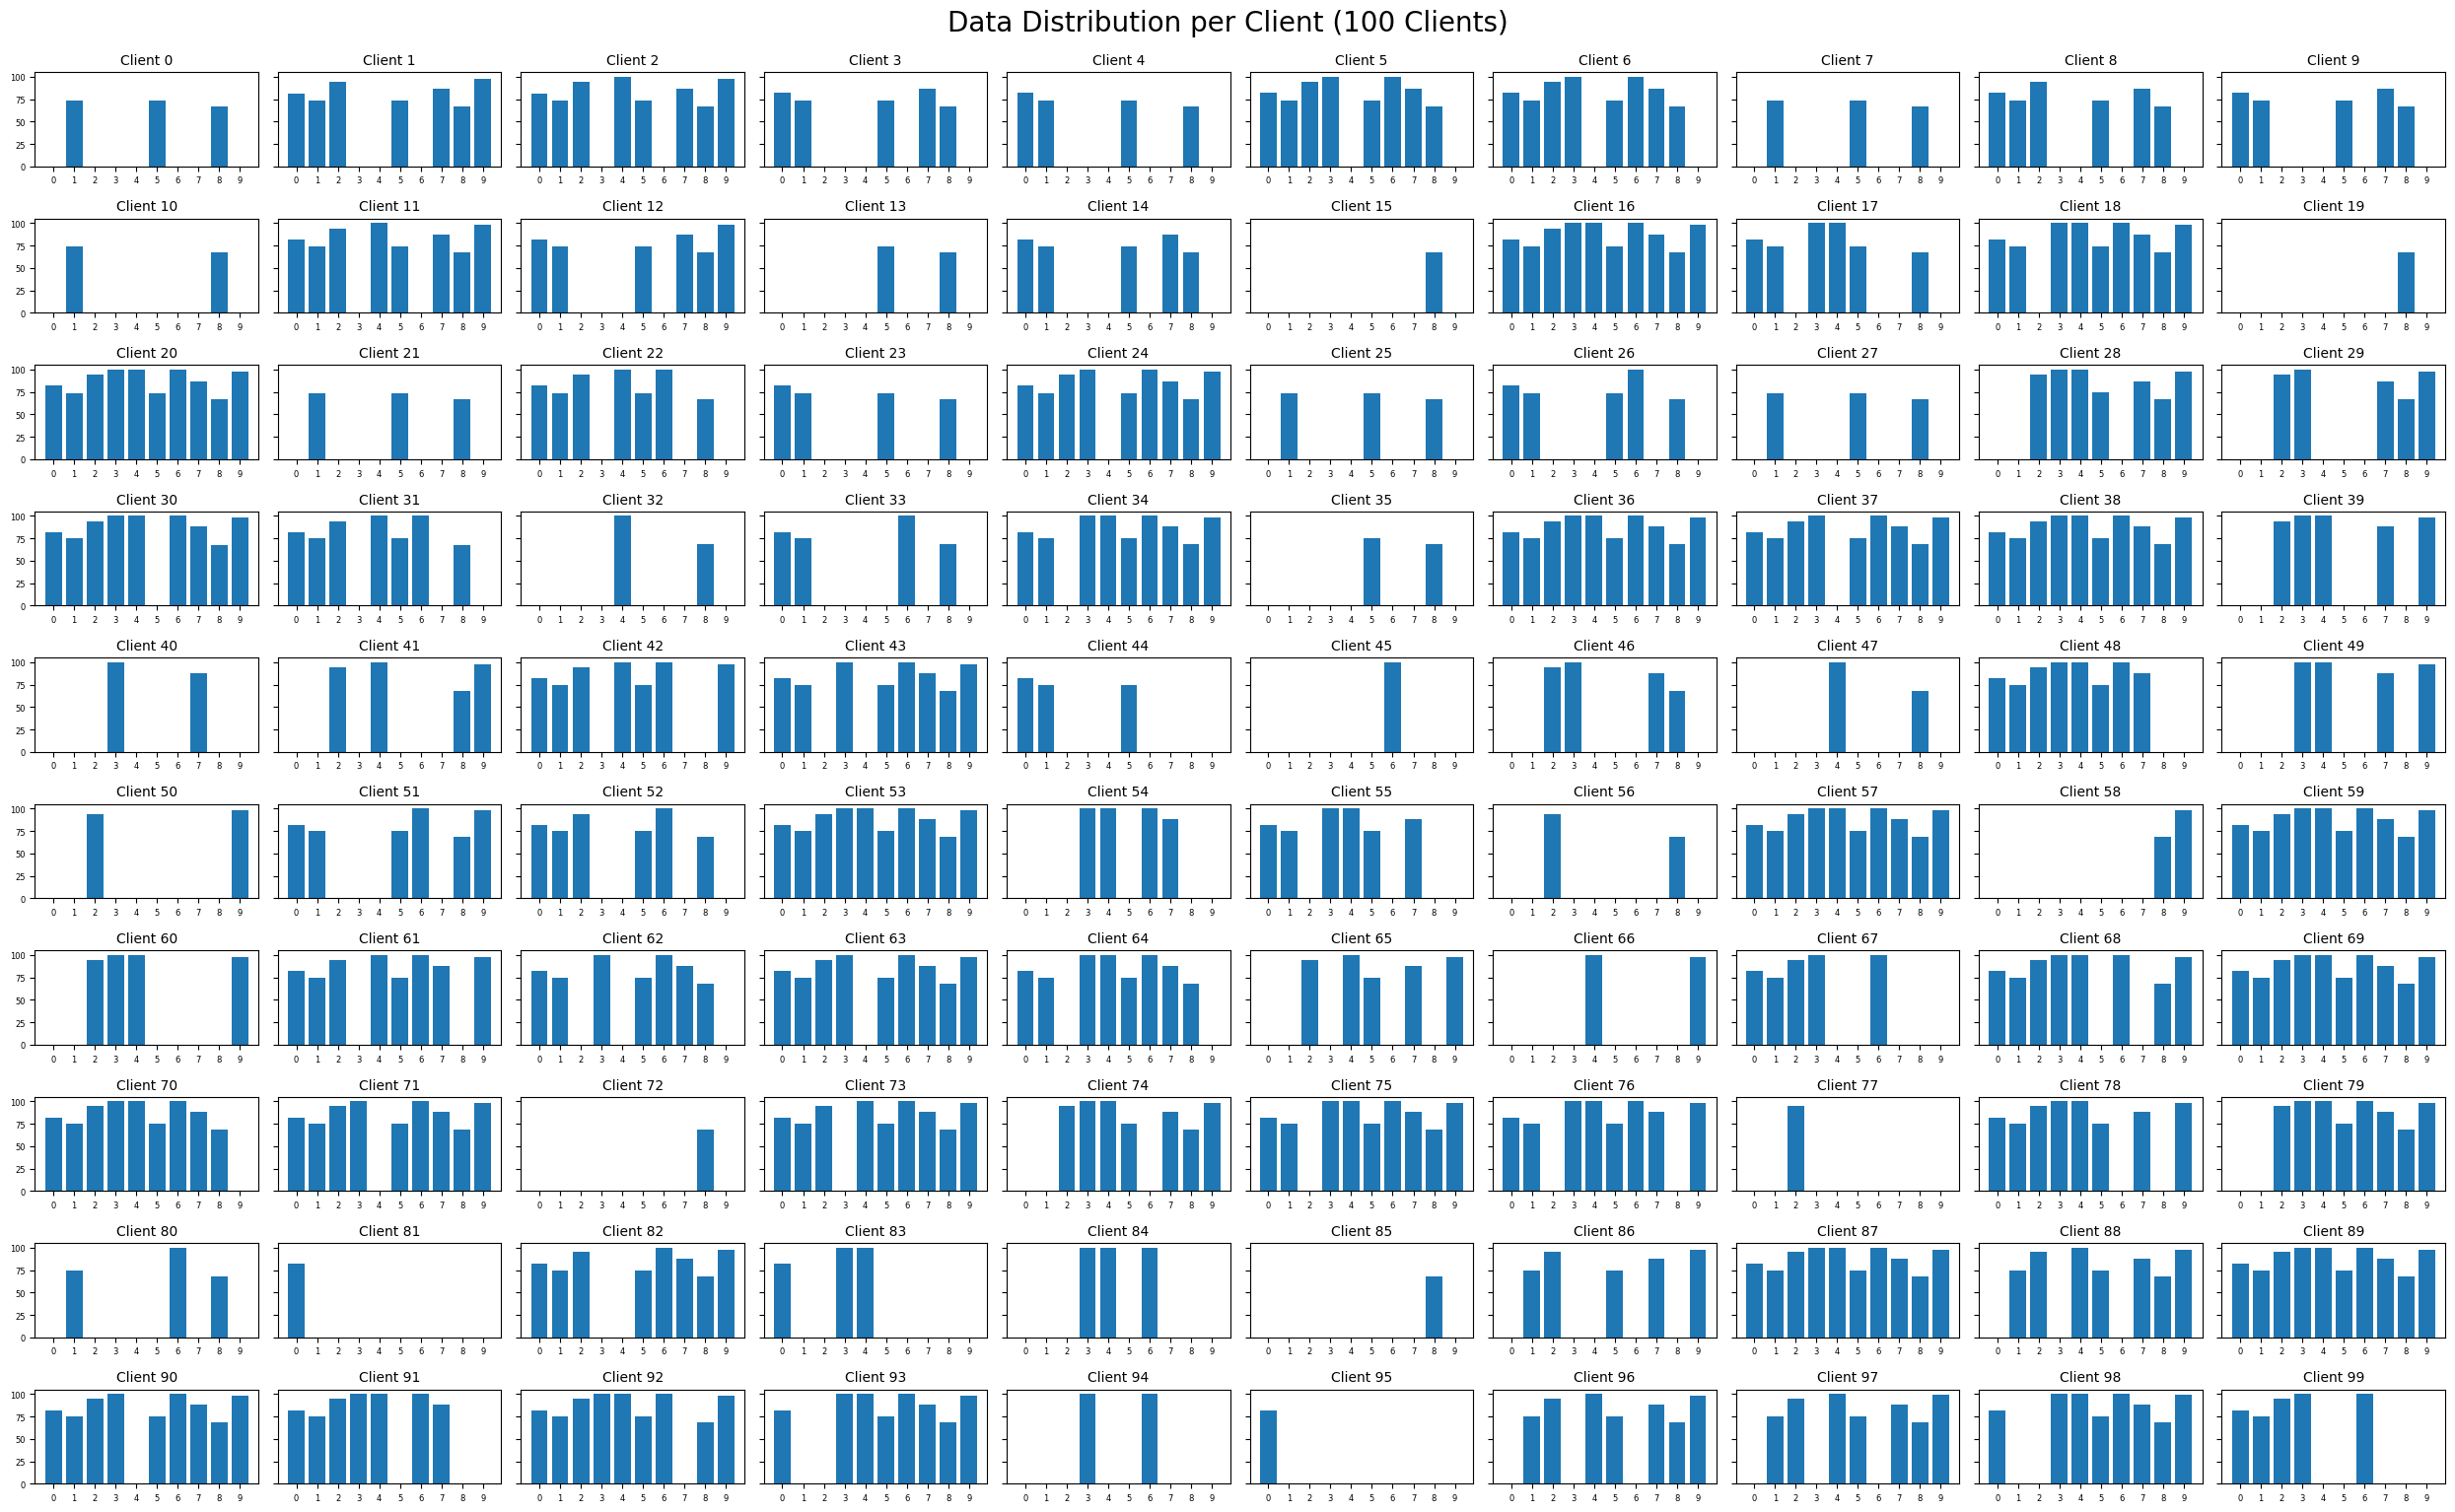

In [32]:
def plot_client_data_distribution_from_loaders(client_dataloader_list, num_clients, num_classes=10):
    rows, cols = 10, 10
    fig, axs = plt.subplots(rows, cols, figsize=(25, 15), sharey=True)
    axs = axs.flatten()

    # Iterate up to the actual number of dataloaders available
    num_available_clients = len(client_dataloader_list)

    for i in range(num_available_clients):
        trainloader = client_dataloader_list[i]
        label_counts = defaultdict(int)


        for _, labels in trainloader:
            for label in labels:
                label_counts[int(label)] += 1

        labels = list(range(num_classes))
        counts = [label_counts[lbl] for lbl in labels]

        axs[i].bar(labels, counts)
        axs[i].set_title(f'Client {i}', fontsize=10)
        axs[i].set_xticks(range(num_classes))
        axs[i].set_xticklabels(range(num_classes), fontsize=6)
        axs[i].tick_params(axis='y', labelsize=6)

    # Hide any unused subplots if num_available_clients < rows*cols
    for j in range(num_available_clients, len(axs)):
        axs[j].axis('off')

    plt.tight_layout()
    plt.suptitle(f"Data Distribution per Client ({num_available_clients} Clients)", fontsize=20, y=1.02)
    plt.show()

# Plot for 100 clients
plot_client_data_distribution_from_loaders(client_dataloader_list, num_clients=NUM_CLIENTS, num_classes=10)

## JS Measures

In [33]:
def calculate_label_distribution(client_dataloader):
    all_labels = []
    for _, labels in client_dataloader:
        all_labels.extend(labels.tolist())

    label_counts = Counter(all_labels)
    for i in range(10):
        label_counts.setdefault(i, 0)
    sorted_distribution = dict(sorted(label_counts.items()))
    return sorted_distribution

def calculate_js_divergence(client_dist, reference_dist):
    client_counts = np.array([client_dist[i] for i in range(10)], dtype=np.float32)
    reference_counts = np.array([reference_dist[i] for i in range(10)], dtype=np.float32)

    client_probs = client_counts / client_counts.sum() if client_counts.sum() > 0 else np.zeros_like(client_counts)
    reference_probs = reference_counts / reference_counts.sum()

    return jensenshannon(client_probs, reference_probs, base=2.0) #** 2

def calculate_js_divergence_manualy(client_dist, reference_dist):
    client_counts = np.array([client_dist[i] for i in range(10)], dtype=np.float32)
    reference_counts = np.array([reference_dist[i] for i in range(10)], dtype=np.float32)

    # Normalize to probabilities
    client_probs = client_counts / client_counts.sum() if client_counts.sum() > 0 else np.zeros_like(client_counts)
    reference_probs = reference_counts / reference_counts.sum()

    # Mixture distribution
    m = 0.5 * (client_probs + reference_probs)

    # Small epsilon to avoid log(0)
    eps = 1e-12
    client_probs = np.clip(client_probs, eps, 1)
    reference_probs = np.clip(reference_probs, eps, 1)
    m = np.clip(m, eps, 1)

    # KL divergence function
    def kl_divergence(p, q):
        return np.sum(p * np.log2(p / q))

    # Jensen-Shannon divergence (always between 0 and 1)
    js_div = 0.5 * kl_divergence(client_probs, m) + 0.5 * kl_divergence(reference_probs, m)

    return js_div

reference_distribution = {0:6000, 1:6000, 2:6000, 3:6000, 4:6000, 5:6000, 6:6000, 7:6000, 8:6000, 9:6000}


In [34]:
js_values = []
for i in range(NUM_CLIENTS):
    client_dist = calculate_label_distribution(client_dataloader_list[i])
    js_value = calculate_js_divergence_manualy(client_dist, reference_distribution)
    js_values.append(js_value)
    print(f"Client {i}: JS Divergence = {js_value}")

Client 0: JS Divergence = 0.4936026930809021
Client 1: JS Divergence = 0.17164084315299988
Client 2: JS Divergence = 0.11104105412960052
Client 3: JS Divergence = 0.31226661801338196
Client 4: JS Divergence = 0.3963414430618286
Client 5: JS Divergence = 0.11116015166044235
Client 6: JS Divergence = 0.11116015166044235
Client 7: JS Divergence = 0.4936026930809021
Client 8: JS Divergence = 0.23818114399909973
Client 9: JS Divergence = 0.31226661801338196
Client 10: JS Divergence = 0.6101348400115967
Client 11: JS Divergence = 0.11102204769849777
Client 12: JS Divergence = 0.23856285214424133
Client 13: JS Divergence = 0.6101348400115967
Client 14: JS Divergence = 0.31226661801338196
Client 15: JS Divergence = 0.758276641368866
Client 16: JS Divergence = 0.0035001710057258606
Client 17: JS Divergence = 0.23966358602046967
Client 18: JS Divergence = 0.05549134686589241
Client 19: JS Divergence = 0.758276641368866
Client 20: JS Divergence = 0.0035001710057258606
Client 21: JS Divergence = 0

In [35]:
js_values = []
for i in range(NUM_CLIENTS):
    client_dist = calculate_label_distribution(client_dataloader_list[i])
    js_value = calculate_js_divergence(client_dist, reference_distribution)
    js_values.append(js_value)
    print(f"Client {i}: JS Divergence = {js_value}")

Client 0: JS Divergence = 0.7025686277641839
Client 1: JS Divergence = 0.41429562825471117
Client 2: JS Divergence = 0.3332281766857117
Client 3: JS Divergence = 0.5588082143289214
Client 4: JS Divergence = 0.6295565218209797
Client 5: JS Divergence = 0.33340686438769934
Client 6: JS Divergence = 0.33340686438769934
Client 7: JS Divergence = 0.7025686277641839
Client 8: JS Divergence = 0.4880380937355359
Client 9: JS Divergence = 0.5588082143289214
Client 10: JS Divergence = 0.7811113213034259
Client 11: JS Divergence = 0.33319974099471017
Client 12: JS Divergence = 0.488428964574116
Client 13: JS Divergence = 0.7811113213034259
Client 14: JS Divergence = 0.5588082143289214
Client 15: JS Divergence = 0.8707908285769029
Client 16: JS Divergence = 0.05916223528853312
Client 17: JS Divergence = 0.48955445447702384
Client 18: JS Divergence = 0.2355660484530369
Client 19: JS Divergence = 0.8707908285769029
Client 20: JS Divergence = 0.05916223528853312
Client 21: JS Divergence = 0.702568627

In [36]:
sample_dist_1 = {0:1, 1:0, 2:0, 3:0, 4:0, 5:0, 6:0, 7:0, 8:0, 9:0}
sample_dist_2 = {0:0, 1:0, 2:0, 3:6000, 4:6000, 5:6000, 6:6000, 7:6000, 8:6000, 9:6000}
js_value = calculate_js_divergence(sample_dist_1, reference_distribution)
print(f"JS Divergence = {js_value}")

JS Divergence = 0.8707908285769029


In [37]:
js_agg_weights = []
js_threshold = 1 #0.8707908285769029

for i in range(NUM_CLIENTS):
    client_dist = calculate_label_distribution(client_dataloader_list[i])
    js_value = calculate_js_divergence(client_dist, reference_distribution)
    agg_weight = js_threshold - js_value
    if agg_weight < 0:
        agg_weight = 0
    js_agg_weights.append(agg_weight)
    print(f"Client {i}: JS Divergence Based Agg Weight = {agg_weight}")

Client 0: JS Divergence Based Agg Weight = 0.29743137223581606
Client 1: JS Divergence Based Agg Weight = 0.5857043717452888
Client 2: JS Divergence Based Agg Weight = 0.6667718233142883
Client 3: JS Divergence Based Agg Weight = 0.44119178567107864
Client 4: JS Divergence Based Agg Weight = 0.37044347817902035
Client 5: JS Divergence Based Agg Weight = 0.6665931356123007
Client 6: JS Divergence Based Agg Weight = 0.6665931356123007
Client 7: JS Divergence Based Agg Weight = 0.29743137223581606
Client 8: JS Divergence Based Agg Weight = 0.511961906264464
Client 9: JS Divergence Based Agg Weight = 0.44119178567107864
Client 10: JS Divergence Based Agg Weight = 0.21888867869657413
Client 11: JS Divergence Based Agg Weight = 0.6668002590052898
Client 12: JS Divergence Based Agg Weight = 0.511571035425884
Client 13: JS Divergence Based Agg Weight = 0.21888867869657413
Client 14: JS Divergence Based Agg Weight = 0.44119178567107864
Client 15: JS Divergence Based Agg Weight = 0.1292091714230

## Models


### Normal CNN Model

In [38]:
# Define the CNN model
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.fc1 = nn.Linear(128 * 4 * 4, 256)
        self.fc2 = nn.Linear(256, 128)
        self.fc3 = nn.Linear(128, 10)
        self.dropout = nn.Dropout(0.5)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))  # [B, 32, 16, 16]
        x = self.pool(F.relu(self.conv2(x)))  # [B, 64, 8, 8]
        x = self.pool(F.relu(self.conv3(x)))  # [B, 128, 4, 4]
        x = x.view(-1, 128 * 4 * 4)           # Flatten
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x

### VGG Model

In [39]:
cfg = {
    'VGG11': [64, 'M', 128, 'M', 256, 256, 'M', 512, 512, 'M', 512, 512, 'M'],
    'VGG13': [64, 64, 'M', 128, 128, 'M', 256, 256, 'M', 512, 512, 'M', 512, 512, 'M'],
    'VGG16': [64, 64, 'M', 128, 128, 'M', 256, 256, 256, 'M', 512, 512, 512, 'M', 512, 512, 512, 'M'],
    'VGG19': [64, 64, 'M', 128, 128, 'M', 256, 256, 256, 256, 'M', 512, 512, 512, 512, 'M', 512, 512, 512, 512, 'M'],
}

class VGG(nn.Module):
    def __init__(self, vgg_name):
        super(VGG, self).__init__()
        self.features = self._make_layers(cfg[vgg_name])
        self.classifier = nn.Sequential(
            nn.Linear(512, 512),
            nn.ReLU(True),
            nn.Linear(512, 512),
            nn.ReLU(True),
            nn.Linear(512, 10)
        )

    def forward(self, x):
        out = self.features(x)
        out = out.view(out.size(0), -1)
        out = self.classifier(out)
        output = F.log_softmax(out, dim=1)
        return output

    def _make_layers(self, cfg):
        layers = []
        in_channels = 3
        for x in cfg:
            if x == 'M':
                layers += [nn.MaxPool2d(kernel_size=2, stride=2)]
            else:
                layers += [nn.Conv2d(in_channels, x, kernel_size=3, padding=1),
                           nn.BatchNorm2d(x),
                           nn.ReLU(inplace=True)]
                in_channels = x
        layers += [nn.AvgPool2d(kernel_size=1, stride=1)]
        return nn.Sequential(*layers)

In [40]:
class Server:

    def __init__(self):
        self.device = DEVICE
        self.model = VGG('VGG19').to(self.device)
        global_testset = torchvision.datasets.CIFAR10(
            root='./data',
            train=False, download=True,
            transform=transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))]))
        global_testset_loader = DataLoader(global_testset, batch_size=100)
        self.testloader = global_testset_loader

        self.algo = SIGN_ALGO # Initialize the algo attribute
        # Get the OQS signer object and public key
        self.signer_object, self.public_key = get_signing_key(self.algo)
        # Pass the OQS signer object directly to the Signature wrapper for OQS algorithms
        self.signer = Signature(SIGN_ALGO, self.signer_object if SIGN_ALGO in ["ML-DSA-44", "Falcon-512"] else self.signer_object)

        self.kem = KEM(KEM_ALGO)
        self.kem_private_key, self.kem_public_key = self.kem.keyGen()
        self.crypto =  Crypto(ENC_ALGO)
        self.clients_info = {} # Dictionary to store client information
        self.enc_key = None
        self.enc_key2 = None
        self.crypto_rsa = Asymatric_crypto(algo="RSA")
        if SECURITY == "ON" and (ENC_ALGO == "ascon80pq" or ENC_ALGO == "ascon128a"):
            self.nonce = os.urandom(16)
        elif SECURITY == "ON" and ENC_ALGO == "AES-GCM":
            self.nonce = os.urandom(12)
        else:
            self.nonce = None

        # Define message tags as byte strings
        self.message_tags = {
            "server_kem_key": b"server_kem",
            "client_model_update": b"client_model",
            "client_additional_data": b"client_additional",
            "client_encapsulation": b"client_encapsulation",
            "server_model_params": b"server_model",
            "server_encryption_key": b"server_enc_key",
            "server_weighted_accuracy": b"server_weighted_accuracy",
            "server_model_update": b"server_model_update"
        }
        self.client_pool = []

    # ==========================================================================

    def add_client_info(self, client_id, client_pk, kem_public_key= None, shared_key=None, nonce=None, rsa_public_key=None):
        """Adds or updates client information."""
        self.clients_info[client_id] = {
            "public_key": client_pk,
            "shared_key": shared_key,
            "kem_public_key": kem_public_key,
            "nonce": nonce,
            "rsa_public_key": rsa_public_key,
            "combine_nonce": None
        }

    def get_client_info(self, client_id):
        """Retrieves client information."""
        return self.clients_info.get(client_id)

    def update_client_shared_key(self, client_id, shared_key):
        """Updates the session key for a specific client."""
        if client_id in self.clients_info:
            self.clients_info[client_id]["shared_key"] = shared_key
        else:
            print(f"Warning: Client {client_id} not found in server records.")

    def signature_verify(self, signature, encrypted_ct, encrypted_key, Nc, client_id):
        client_info =  self.get_client_info(client_id)
        if not client_info:
            print(f"Client {client_id} not found in server records.")
            return False
        client_pk = client_info["public_key"]
        self.signer.verification(encrypted_ct, signature, client_pk)
        ct = self.decrypt_kem_cipher(encrypted_ct, encrypted_key, Nc, client_id)

        return ct

    def decapsulation(self, ct, client_id):
        if KEM_ALGO == "ECDH":
          client_info =  self.get_client_info(client_id)
          if not client_info:
              print(f"Client {client_id} not found in server records.")
              return None
          client_enc_pk = client_info["kem_public_key"]
          shared_key = self.kem.decaps(sk = self.kem_private_key, pk = client_enc_pk, ct = ct)
        else:
          shared_key = self.kem.decaps(sk = self.kem_private_key,pk = self.kem_public_key,ct = ct)
        self.update_client_shared_key(client_id, shared_key)

    def get_encryption_key(self, client_id, accuracy_test):
        client_info =  self.get_client_info(client_id)
        shared_key = client_info["shared_key"]
        client_nonce = client_info["nonce"]
        combine_nonce = client_info["combine_nonce"]
        if not shared_key:
            print(f"Shared key not found for client {client_id}.")
            return None

        if accuracy_test == True:
          key_bytes = self.enc_key2
        else:
          key_bytes = self.enc_key
        timestamp = f"{time.time():.6f}".encode('utf-8')
        message_tag_bytes = self.message_tags.get("server_encryption_key", b"server_enc_key")
        data_to_encrypt = key_bytes + timestamp

        ad = str(client_id).encode('utf-8') + b"|" + message_tag_bytes + b"|" + shared_key

        encrypt_key, returned_nonce = self.crypto.encryprion(shared_key, data_to_encrypt, ad, combine_nonce)
        return encrypt_key, returned_nonce


    def get_encrypt_modelparams(self):

        model_params = self.model.state_dict()
        quantized_dict, metadata = quantize_model_parameters(model_params, num_bits=8)
        serialized_data = serialize_quantized_model(quantized_dict, metadata)

        timestamp = f"{time.time():.6f}".encode('utf-8')
        data_to_encrypt = serialized_data + timestamp

        # Generate a NEW symmetric key for this encryption
        if self.crypto.algo == "ascon80pq":
            self.enc_key = os.urandom(key_lengths["ascon80pq"])
        elif self.crypto.algo == "ascon128a":
            self.enc_key = os.urandom(key_lengths["ascon128a"])
        elif self.crypto.algo == "AES-GCM":
            self.enc_key = os.urandom(32)
        else:
             raise ValueError(f"Unsupported encryption algorithm for generating new key: {self.crypto.algo}")

        message_tag = self.message_tags.get("server_model_update", b"server_model_update")

        ad = str(self.public_key).encode('utf-8') + b"|" + message_tag
        encrypt_params, nonce = self.crypto.encryprion(self.enc_key,data_to_encrypt, ad, self.nonce)
        # compress_encrypt_params = compress_model_params =(encrypt_params)
        return encrypt_params, nonce  # replace encrypt_params -> compress_encrypt_params

    def decrypt(self, cipher,nonce,ad, client_id):
        client_info =  self.get_client_info(client_id)
        shared_key = client_info["shared_key"]
        if not shared_key:
            print(f"Shared key not found for client {client_id}.")
            return None
        return self.crypto.decryption(cipher,shared_key, nonce,ad = ad)

    def decrypt_and_load_model(self, packet):

      # comressed_cipher  = packet['cipher']
      # cipher = decompress_model_param(comressed_cipher)
        cipher = packet['cipher']  # remove this
        nonce = packet['nonce']
        client_id = packet["client_id"]

        client_info = self.get_client_info(client_id)
        shared_key = client_info["shared_key"]
        message_tag_bytes = self.message_tags.get("client_model_update")
        ad = str(client_id).encode('utf-8') + b"|" + message_tag_bytes + b"|" + shared_key


        print(f"decrypting modelparams Client ID: {client_id}")
        decrypted_data = self.decrypt(cipher, nonce,ad, client_id)
                # 4. Split into key and timestamp
        TIMESTAMP_LEN = len(f"{time.time():.6f}".encode('utf-8'))
        serialized_data = decrypted_data[:-TIMESTAMP_LEN]
        timestamp_bytes = decrypted_data[-TIMESTAMP_LEN:]

        try:
            timestamp = float(timestamp_bytes.decode('utf-8'))
        except Exception:
            raise ValueError("Invalid timestamp format in decrypted data.")

        # 5. Validate timestamp (±30s skew allowed)
        current_time = time.time()
        allowed_skew = 300
        if not (current_time - allowed_skew <= timestamp <= current_time + allowed_skew):
            raise ValueError(f"Timestamp out of valid range: {timestamp}")


        quantized, metadata = deserialize_quantized_model(serialized_data)

        dequantized_params = dequantize_model_parameters(
            quantized,
            metadata,
            DEVICE
        )

        print(f"\n[Server] Received model from Client {packet['client_id']} | Round {packet['round']} Timings:")
        return {
            "client_id": client_id,
            "model_params": dequantized_params
        }

    def decrypt_aditional_data(self, data):
        adition_data_cipher = data["aditional_data_cipher"]
        aditional_data_enc_nonce = data["aditional_data_enc_nonce"]
        client_id = data["client_id"]

        client_info = self.get_client_info(client_id)
        shared_key = client_info["shared_key"]

        message_tag_bytes = self.message_tags.get("client_model_update")
        ad = str(client_id).encode('utf-8') + b"|" + message_tag_bytes + b"|" + shared_key

        decrypted_data = self.decrypt(adition_data_cipher, aditional_data_enc_nonce, ad, client_id)

        TIMESTAMP_LEN = len(f"{time.time():.6f}".encode('utf-8'))
        adition_data_bytes = decrypted_data[:-TIMESTAMP_LEN]
        timestamp_bytes = decrypted_data[-TIMESTAMP_LEN:]

        try:
            timestamp = float(timestamp_bytes.decode('utf-8'))
        except Exception:
            raise ValueError("Invalid timestamp format in decrypted data.")

        # 5. Validate timestamp (±30s skew allowed)
        current_time = time.time()
        allowed_skew = 300
        if not (current_time - allowed_skew <= timestamp <= current_time + allowed_skew):
            raise ValueError(f"Timestamp out of valid range: {timestamp}")



        adition_data = adition_data_bytes.decode('utf-8')
        return {
                 "client_id": client_id,
                  "IID_measurement": float(adition_data)
              }


    def aggregate_update(self, clients_model_list, agg_weights=None):

        if SECURITY == "ON":

            decry_start_server = time.time()

            # 🔹 Step 1 — decrypt models
            decry_start = time.time()
            model_objs = [
                self.decrypt_and_load_model(pkt)
                for pkt in clients_model_list
            ]
            print(f"decry_time mode (server) : {time.time() - decry_start}")

            # 🔹 Step 2 — decrypt IID measurements (ONLY if exist)
            iid_list = []
            if agg_weights is not None:

                decry_ad_start = time.time()

                for data in agg_weights:

                    # 🔹 skip if encrypted additional data missing
                    if (
                        data.get("aditional_data_cipher") is None or
                        data.get("aditional_data_enc_nonce") is None
                    ):
                        print(f"Skipping IID decrypt — missing data for client {data.get('client_id')}")
                        continue

                    iid_obj = self.decrypt_aditional_data(data)
                    iid_list.append(iid_obj)

                print(f"decry_ad_time mode (server) : {time.time() - decry_ad_start}")

            # 🔹 convert empty list to None for later logic
            if len(iid_list) == 0:
                 iid_list = None
            # if agg_weights is not None:
            #     decry_ad_start = time.time()
            #     iid_list = [
            #         self.decrypt_aditional_data(data)
            #         for data in agg_weights
            #     ]
            #     print(f"decry_ad_time mode (server) : {time.time() - decry_ad_start}")

            accuracy_list = None


            # 🔹 Step 3 — client pool + validation (ONLY if IID exist + CAFA mode)
            if iid_list is not None and IID_MEASURE_METHOD == "CAFA":

                self.client_pool = self.update_client_pool(
                    iid_list,
                    self.client_pool
                )

                accuracy_list = []

                for obj in model_objs:
                    result = self.test_client_model(
                        obj["model_params"],
                        obj["client_id"]
                    )
                    accuracy_list.append(result)

            # 🔹 Step 4 — calculate weights
            if iid_list is not None:
                final_weight_objs = self.calculate_client_weights(
                    iid_list,
                    accuracy_list
                )

                weight_dict = {
                    w["client_id"]: w["client_weight"]
                    for w in final_weight_objs
                }

                ordered_models = []
                ordered_weights = []

                for obj in model_objs:
                    cid = obj["client_id"]

                    if cid not in weight_dict:
                        print(f"Warning: missing weight for client {cid}")
                        continue

                    ordered_models.append(obj["model_params"])
                    ordered_weights.append(weight_dict[cid])

            else:
                # 🔹 fallback → no weights provided
                print("Info: No agg_weights provided — using equal weights")

                ordered_models = [obj["model_params"] for obj in model_objs]
                ordered_weights = None

            print(f"decry_total mode (server) : {time.time() - decry_start_server}")

        else:
            ordered_models = clients_model_list
            ordered_weights = agg_weights

        return self.aggregate_models(
            ordered_models,
            ordered_weights
        )

#===================

    # def aggregate_update(self, clients_model_list, agg_weights=None):

    #     if SECURITY == "ON":

    #         decry_start_server = time.time()

    #         # 🔹 Step 1 — decrypt models
    #         decry_start = time.time()
    #         model_objs = [
    #             self.decrypt_and_load_model(pkt)
    #             for pkt in clients_model_list
    #         ]
    #         print(f"decry_time mode (server) : {time.time() - decry_start}")

    #         # 🔹 Step 2 — decrypt IID measurements
    #         decry_ad_start = time.time()
    #         iid_list = [
    #             self.decrypt_aditional_data(data)
    #             for data in agg_weights
    #         ]
    #         print(f"decry_ad_time mode (server) : {time.time() - decry_ad_start}")

    #         if IID_MEASURE_METHOD == "CAFA":

    #             # 🔹 Step 3 — update client pool
    #             self.client_pool = self.update_client_pool(
    #                 iid_list,
    #                 self.client_pool
    #             )

    #             # 🔹 Step 4 — test each model
    #             accuracy_list = []

    #             for obj in model_objs:

    #                 result = self.test_client_model(
    #                     obj["model_params"],
    #                     obj["client_id"]
    #                 )

    #                 accuracy_list.append(result)
    #         else :
    #             accuracy_list=None

    #         # 🔹 Step 5 — calculate final client weights
    #         final_weight_objs = self.calculate_client_weights(
    #             iid_list,
    #             accuracy_list
    #         )

    #         # 🔹 Step 6 — align order with model list
    #         weight_dict = {
    #             w["client_id"]: w["client_weight"]
    #             for w in final_weight_objs
    #         }

    #         ordered_models = []
    #         ordered_weights = []

    #         for obj in model_objs:
    #             cid = obj["client_id"]

    #             if cid not in weight_dict:
    #                 print(f"Warning: missing weight for client {cid}")
    #                 continue

    #             ordered_models.append(obj["model_params"])
    #             ordered_weights.append(weight_dict[cid])

    #         print(f"decry_total mode (server) : {time.time() - decry_start_server}")

    #     else:
    #         ordered_models = clients_model_list
    #         ordered_weights = agg_weights

    #     # 🔹 Final aggregation
    #     return self.aggregate_models(
    #         ordered_models,
    #         ordered_weights
    #     )

    # def aggregate_update(self, clients_model_list, agg_weights=None):

    #     if SECURITY == "ON":
    #       decry_start_server = time.time()
    #       decry_start = time.time()
    #       models = [self.decrypt_and_load_model(pkt) for pkt in clients_model_list]
    #       decry_time = time.time() - decry_start
    #       print(f"decry_time mode (server) : {decry_time}")

    #       decry_ad_start = time.time()
    #       weights = [self.decrypt_aditional_data(data) for data in  agg_weights]
    #       decry_ad_time = time.time() - decry_ad_start
    #       print(f"decry_ad_time mode (server) : {decry_ad_time}")

    #       self.client_pool = update_client_pool(
    #           weights,
    #           self.client_pool
    #       )
    #       test_client_model(self, client_model, client_id)

    #       decry_total = time.time() - decry_start_server
    #       print(f"decry_total mode (server) : {decry_total}")



    #     else:
    #       models = clients_model_list
    #       weights = agg_weights

    #     return self.aggregate_models(models, weights)

    def encrypt_signatur(self, signature, client_id):
        """
        Encrypts the signature, a timestamp, a nonce, and a message tag using RSA encryption.
        """
        client_info = self.get_client_info(client_id)
        if not client_info or not client_info.get("rsa_public_key"):
            print(f"Client {client_id} not found or RSA public key not available.")
            return None

        client_rsa_public_key = client_info["rsa_public_key"]

        # Combine data to encrypt
        timestamp = str(time.time()).encode('utf-8')
        message_tag_bytes = self.message_tags.get("server_kem_key", b"")

        data_to_encrypt = signature + timestamp + message_tag_bytes

        aes_key = os.urandom(32)

        # Associated data
        ad = str(client_id).encode('utf-8')

        # Encrypt data with AES
        encrypted_signature, nonce = self.crypto.encryprion(aes_key, data_to_encrypt, ad, self.nonce)

        # Encrypt the combined data using the client's RSA public key
        encrypted_key = self.crypto_rsa.encryprion(aes_key, client_rsa_public_key)

        # You might want to return the encrypted data
        return encrypted_signature, encrypted_key, nonce

    def decrypt_kem_cipher(self, encrypted_ct, encrypted_key, nonce, client_id):


        # 1. Retrieve client info
        client_info = self.get_client_info(client_id)
        if not client_info or not client_info.get("rsa_public_key"):
            print(f"Client {client_id} not found or RSA public key not available.")
            return None

        # 2. Decrypt AES key using the server's RSA private key
        aes_key = self.crypto_rsa.decryption(encrypted_key)

        # 3. Decrypt data using AES (or Ascon) with AD = server ID
        ad = str(client_id).encode('utf-8')
        decrypted_data = self.crypto.decryption(encrypted_ct, aes_key, nonce, ad)

        # 4. Get expected tag
        expected_tag = self.message_tags.get("client_encapsulation")
        if not expected_tag:
            raise ValueError("Unknown tag key: client_encapsulation")

        tag_len = len(expected_tag)

        # 5. Determine lengths
        if ENC_ALGO == "AES-GCM":
            NONCE_LEN = 12
        elif ENC_ALGO in ["ascon80pq", "ascon128a"]:
            NONCE_LEN = 16
        else:
            NONCE_LEN = 0

        TIMESTAMP_LEN = len(f"{time.time():.6f}".encode('utf-8'))
        SERVER_NONCE_LEN = len(self.nonce)

        # 6. Validate message tag
        if not decrypted_data.endswith(expected_tag):
            raise ValueError("Decryption failed: message tag mismatch.")

        # 7. Split structure: [ct][timestamp][nonce][server_nonce][tag]
        tag_start = len(decrypted_data) - tag_len
        server_nonce_start = tag_start - SERVER_NONCE_LEN
        nonce_start = server_nonce_start - NONCE_LEN
        timestamp_start = nonce_start - TIMESTAMP_LEN
        ct_end = timestamp_start

        ct = decrypted_data[:ct_end]
        timestamp_bytes = decrypted_data[timestamp_start:nonce_start]
        client_nonce = decrypted_data[nonce_start:server_nonce_start]
        server_nonce = decrypted_data[server_nonce_start:tag_start]
        tag = decrypted_data[tag_start:]

        # 8. Validate timestamp (\u00b15 min)
        try:
            timestamp = float(timestamp_bytes.decode("utf-8"))
        except Exception:
            raise ValueError("Invalid timestamp format in decrypted data.")

        current_time = time.time()
        if abs(current_time - timestamp) > 300:
            raise ValueError("Decryption rejected: timestamp too old or invalid.")

        # 9. Validate server nonce consistency
        print(f"recived server nonce : {server_nonce}")
        print(f"local server nonce : {self.nonce}")
        if server_nonce != self.nonce:
            raise ValueError("Server nonce mismatch \u2014 possible tampering detected.")

        combined_nonce_seed = self.nonce + client_nonce
        new_nonce_for_encryption = hashlib.sha256(combined_nonce_seed).digest()[:nonce_len]
        # 10. Store client nonce for tracking
        self.clients_info[client_id]["nonce"] = client_nonce
        self.clients_info[client_id]["combine_nonce"] = new_nonce_for_encryption
        print(f"updated client nonce : {self.clients_info[client_id]['nonce']}")
        print(f"updated combine nonce : {self.clients_info[client_id]['combine_nonce']}")
        # 11. Return plaintext components
        return ct

#=============================================================

    # FedAvg Algorithm
    def fed_avg(self, client_models_param_list):
        avg_params = copy.deepcopy(client_models_param_list[0])
        for key in avg_params:
            for i in range(1, len(client_models_param_list)):
                avg_params[key] += client_models_param_list[i][key]
            # Explicitly cast to float before division and back to original type
            avg_params[key] = (avg_params[key].float() / len(client_models_param_list)).to(avg_params[key].dtype)
        return avg_params

    # Weighted FedAvg
    def weighted_fed_avg(self, models_params, weights):
        avg_params = copy.deepcopy(models_params[0])
        total_weight = sum(weights)
        for param_key in avg_params:
            # Handle quantized parameters by temporarily dequantizing, averaging, and requantizing
            if hasattr(avg_params[param_key], '_scale') and hasattr(avg_params[param_key], '_zero_point'):
                # This is a quantized tensor. Dequantize, average, and then we'll re-quantize later.
                # For true quantized aggregation, more complex logic is needed.
                weighted_sum = torch.zeros_like(avg_params[param_key], dtype=torch.float)
                for i in range(len(models_params)):
                    # Temporarily dequantize client parameter for aggregation
                    client_param = models_params[i][param_key].dequantize()
                    weighted_sum += client_param * weights[i]
                avg_params[param_key] = weighted_sum / total_weight
            else:
                # Handle non-quantized parameters (e.g., biases)
                weighted_sum = torch.zeros_like(avg_params[param_key], dtype=torch.float) # Use float for summation
                for i in range(len(models_params)):
                    client_param = models_params[i][param_key].float() # Cast client params to float
                    weighted_sum += client_param * weights[i]
                # Cast back to original type after division
                avg_params[param_key] = (weighted_sum / total_weight).to(avg_params[param_key].dtype)

        return avg_params
    def client_selection_fed_avg(self, models_params, weights):
        print(f"\nAggregate using Client Selection.")
        avg_params = copy.deepcopy(models_params[0])

        selected_clients = 0
        for weight in weights:
          if weight > 0.8:
            selected_clients += 1

        for param_key in avg_params:
            weighted_sum = torch.zeros_like(avg_params[param_key])
            for i in range(1, len(models_params)):
                client_param = models_params[i][param_key]
                if weights[i] > 0.8:
                  weighted_sum += client_param
            print(f"Selected Clients: {selected_clients}")
            avg_params[param_key] = weighted_sum / selected_clients
        return avg_params


    # Assign Weight For Clients based on IID nature mesures (EMD/JS/..)
    def iid_mesure_to_weights(self, client_iid_mesure_list):
        d_min, d_max = min(client_iid_mesure_list), max(client_iid_mesure_list)
        if d_max == d_min:
            return [1.0 for _ in client_iid_mesure_list]  # Avoid div by zero
        return [(1 - (value - d_min) / (d_max - d_min)) for value in client_iid_mesure_list]


    # Aggregation
    def aggregate_models(self, client_models, weights=None):
        if weights is None:
            print(f"\nAggregate using FedAvg.")
            aggregated_model_params_float = self.fed_avg(client_models)

            self.model.load_state_dict(aggregated_model_params_float)
            aggregated_model_params = self.model.state_dict()

        else:
            print(f"\nAggregate using Weighted FedAvg.")
            # Aggregate in float
            aggregated_model_params_float = self.weighted_fed_avg(client_models, weights)

            # Load the aggregated float parameters into the server's model
            # This assumes the server's model is a float model during training.
            self.model.load_state_dict(aggregated_model_params_float)
            aggregated_model_params = self.model.state_dict() # Return the state dict of the updated float model


        return self.model

    # Test Global Model
    def test_model(self):
        self.model.eval()
        correct, total = 0, 0
        total_loss = 0.0
        criterion = F.nll_loss

        with torch.no_grad():
            for images, labels in self.testloader:
                images, labels = images.to(self.device), labels.to(self.device)
                outputs = self.model(images)  # FIXED: self.model
                loss = criterion(outputs, labels)
                total_loss += loss.item() * images.size(0)

                _, predicted = torch.max(outputs, 1)
                correct += (predicted == labels).sum().item()
                total += labels.size(0)

        avg_loss = total_loss / total
        accuracy = 100.0 * correct / total
        return accuracy, avg_loss

    # evaluate silhouette scores for different k
    def evaluate_kmeans_silhouette(self, distribution_matrix, k_range):
        silhouette_scores = []
        for k in k_range:
            kmeans = KMeans(n_clusters=k, random_state=0)
            labels = kmeans.fit_predict(distribution_matrix)
            score = silhouette_score(distribution_matrix, labels)
            silhouette_scores.append(score)
            print(f"k={k}, silhouette score={score:.4f}")
        return silhouette_scores

    def find_optimal_k_and_client_clusters(self, num_clients, distribution_matrix):
        k_range = range(2, num_clients)  # 2 to NUM_CLIENTS - 1

        silhouette_scores = self.evaluate_kmeans_silhouette(distribution_matrix, k_range)

        # Plot silhouette scores vs k
        plt.figure(figsize=(8, 5))
        plt.plot(k_range, silhouette_scores, marker='o')
        plt.title("Silhouette Score vs Number of Clusters (k)")
        plt.xlabel("Number of clusters (k)")
        plt.ylabel("Silhouette Score")
        plt.xticks(k_range)
        ax = plt.gca()
        ax.set_xticklabels(k_range, fontsize=10)
        plt.grid(True)
        plt.show()

        # Best k
        best_k = k_range[np.argmax(silhouette_scores)]
        print(f"\n\u2705 Optimal k = {best_k}, Silhouette Score = {max(silhouette_scores):.4f}")

        kmeans = KMeans(n_clusters=best_k, random_state=0)
        client_cluster_labels = kmeans.fit_predict(distribution_matrix)

        return best_k, silhouette_scores, client_cluster_labels




    def increase_client_usage(self, client_pool, client_id):

      for client in client_pool:
          if client["client_id"] == client_id:
              client["used_terms"] += 1
              return True   # updated successfully

      return False  # client not found


    def test_client_model(self, client_model, client_id):
        print(" test client model in AB --------------------------------------------")
        clients_list = self.client_pool
        selected_clients = [client["client_id"] for client in clients_list]

        client_weighted_val_accuracys = []
        if SECURITY == "ON":
            #model_params = self.decrypt_and_load_model(client_model)
            model_params = client_model

            message_tag = self.message_tags.get("server_weighted_accuracy", b"server_weighted_accuracy")

            ad = str(self.public_key).encode('utf-8') + b"|" + message_tag

            quantized_dict, metadata = quantize_model_parameters(model_params, num_bits=8)
            serialized_data = serialize_quantized_model(quantized_dict, metadata)

            timestamp = f"{time.time():.6f}".encode('utf-8')
            data_to_encrypt = serialized_data + timestamp


                        # Generate a NEW symmetric key for this encryption
            if self.crypto.algo == "ascon80pq":
                  self.enc_key2 = os.urandom(key_lengths["ascon80pq"])
            elif self.crypto.algo == "ascon128a":
                  self.enc_key2 = os.urandom(key_lengths["ascon128a"])
            elif self.crypto.algo == "AES-GCM":
                  self.enc_key2 = os.urandom(32)
            else:
                raise ValueError(f"Unsupported encryption algorithm for generating new key: {self.crypto.algo}")

            # Use the derived_encryption_nonce here
            encrypt_params_for_cafa, model_nonce_for_cafa = self.crypto.encryprion(self.enc_key2, data_to_encrypt, ad, self.nonce)


        for i in range(len(clients_list)):
            client_id_in_list = clients_list[i]
            client = Client(selected_clients[i], server.public_key, server.crypto_rsa.public_key)

            if SECURITY == "ON":

              client_info = server.get_client_info(client.id)

              if client_info is None:
                  print(f"Client {selected_clients[i]} not registerd with server ")
                  client.register()

                  server.add_client_info( client.id, client.public_key, client.kem_public_key, shared_key=None, nonce = client.nonce, rsa_public_key = client.crypto_rsa.public_key)

                  encrypted_signature, encrypted_key, nonce = server.encrypt_signatur(server_signature, client.id)

                  signature = client.decrypt_signature(encrypted_signature, encrypted_key, nonce)

                  client.signature_verify(server_kem_public_key_bytes, signature, server.kem_public_key)
                  client.key_encapsulation()

                  if KEM_ALGO != "ECDH":
                    signature, encrypted_ct, encrypted_key, Nc = client.sign()

                    ct = server.signature_verify(signature, encrypted_ct, encrypted_key, Nc, client.id)

                  server.decapsulation(ct, client.id)
              else:
                  print(f"Client {client_id_in_list} already exists in server records.") # Use client_id_in_list
                  client.public_key = client_info["public_key"]
                  client.shared_key = client_info["shared_key"]
                  client.nonce = client_info["nonce"]
                  client.combine_nonce = client_info["combine_nonce"]
                  client.server_nonce = server.nonce

                  client.kem_server_pk = self.kem_public_key # Retrieve and set server's KEM public key object

              try:
                key_cipher, key_nonce = server.get_encryption_key(client.id, accuracy_test = True)
                client.derive_server_enc_key(key_cipher, key_nonce)


                # # Now decrypt the model parameters for *this* client (client_id_in_list)
                # client_info_current = self.get_client_info(client.id)
                # if not client_info_current:
                #     raise ValueError(f"Client {client.id} not registered for nonce derivation.")
                # client_nonce_current = client_info_current["nonce"]
                # combined_nonce_seed_current = client_nonce_current + self.nonce
                # derived_nonce_for_current_client = hashlib.sha256(combined_nonce_seed_current).digest()[:required_nonce_len]

                client.decrypt(encrypt_params_for_cafa, self.nonce, accuracy_test = True)

              except Exception as e:
                print(f"Error while client getting model update: {e}")
                raise

            else:
              client.model.load_state_dict(model_params)

            weighted_accuracy, weighted_accuracy_nonce = client.calculate_weighted_val_accuracy(client_model = client.model, device=DEVICE)

            if SECURITY == "ON":
              ad = str(client.id).encode('utf-8')
              client_weighted_val_accuracy_bytes = self.decrypt(weighted_accuracy, weighted_accuracy_nonce,ad, client.id)
              adition_data = client_weighted_val_accuracy_bytes.decode('utf-8')
              client_weighted_val_accuracy = float(adition_data)

              #print(f"after encryption -> decryption weighted_accuracy:{client_weighted_val_accuracy}")
              client_weighted_val_accuracys.append(client_weighted_val_accuracy)
            else:
              client_weighted_val_accuracys.append(weighted_accuracy)

            print(f"AB method  teste with client :--------------------------------------------: {client.id}")
            self.increase_client_usage(self.client_pool, client.id)

        avarage_client_weighted_val_accuracy = sum(client_weighted_val_accuracys) / len(client_weighted_val_accuracys)

        print(f"original avarage weight :{avarage_client_weighted_val_accuracy}")

        # if SECURITY == "ON":
        #   avarage_client_weighted_bytes = str(avarage_client_weighted_val_accuracy).encode('utf-8')

        #   client_info =  self.get_client_info(client_id_for_cafa)
        #   shared_key = client_info["shared_key"]
        #   if not shared_key:
        #       print(f"Shared key not found for client {client_id_for_cafa}.")
        #       return None
        #   ad = str(client_id_for_cafa).encode('utf-8')

        #   derived_encryption_nonce = client_info["combine_nonce"]

        #   client_weighted_val_accuracy, client_weighted_val_accuracy_nonce = self.crypto.encryprion(shared_key, avarage_client_weighted_bytes, ad, derived_encryption_nonce)
        # else:
        #   client_weighted_val_accuracy = avarage_client_weighted_val_accuracy
        #   client_weighted_val_accuracy_nonce = None
        client_weighted_val_accuracy = avarage_client_weighted_val_accuracy

        return {
            "client_id":client_id,
            "client_weighted_val_accuracy": client_weighted_val_accuracy
            }

    def update_client_pool(self, weights, client_pool):

        for obj in weights:
            new_client_id = obj["client_id"]
            new_iid = obj["IID_measurement"]

            # 🔹 Step 1: remove overused clients
            client_pool[:] = [
                c for c in client_pool
                if c["used_terms"] < MAX_USED_TERMS
            ]

            # 🔹 Step 2: check if client already exists (avoid duplicates)
            existing_client = next(
                (c for c in client_pool if c["client_id"] == new_client_id),
                None
            )

            if existing_client:
                # update IID value only
                existing_client["IID_measurement"] = new_iid
                continue

            # 🔹 Step 3: if pool has space → add directly
            if len(client_pool) < MAX_CLIENTS_POOL_SIZE:
                client_pool.append({
                    "client_id": new_client_id,
                    "IID_measurement": new_iid,
                    "used_terms": 0
                })
                continue

            # 🔹 Step 4: replace lowest IID client if new higher
            lowest_client = min(
                client_pool,
                key=lambda x: x["IID_measurement"]
            )

            if new_iid > lowest_client["IID_measurement"]:
                client_pool.remove(lowest_client)
                client_pool.append({
                    "client_id": new_client_id,
                    "IID_measurement": new_iid,
                    "used_terms": 0
                })

        return client_pool


    def calculate_client_weights(self, iid_list, accuracy_list=None):

        result = []

        # 🔹 if accuracy_list exists → convert to dict for fast lookup
        accuracy_dict = {}
        if accuracy_list:
            accuracy_dict = {
                item["client_id"]: item["client_weighted_val_accuracy"]
                for item in accuracy_list
            }

        for iid_obj in iid_list:

            client_id = iid_obj["client_id"]
            iid_value = iid_obj["IID_measurement"]

            # 🔹 if accuracy data available for this client
            if accuracy_list and client_id in accuracy_dict:
                accuracy_value = accuracy_dict[client_id]
                client_weight = iid_value * accuracy_value
            else:
                # 🔹 fallback → use IID only
                client_weight = iid_value

            result.append({
                "client_id": client_id,
                "client_weight": client_weight
            })

        return result

    # def calculate_client_weights(self,iid_list, accuracy_list):

    #     # 🔹 convert accuracy list into dict for O(1) lookup
    #     accuracy_dict = {
    #         item["client_id"]: item["client_weighted_val_accuracy"]
    #         for item in accuracy_list
    #     }

    #     result = []

    #     for iid_obj in iid_list:

    #         client_id = iid_obj["client_id"]
    #         iid_value = iid_obj["IID_measurement"]

    #         if client_id not in accuracy_dict:
    #             print(f"Warning: accuracy missing for client {client_id}")
    #             continue

    #         accuracy_value = accuracy_dict[client_id]

    #         client_weight = iid_value * accuracy_value

    #         result.append({
    #             "client_id": client_id,
    #             "client_weight": client_weight
    #         })

    #     return result

In [41]:
client_model_encryption_time = None
client_model_decryprion_time = None
befeore_encryption_model_size = None
after_encryprion_model_size = None
client_traning_time = None
transistion_data_size = None


## Client


In [42]:
class Client:
    def __init__(self, id, server_pk, server_rsa_public_key):
        self.id = id
        self.device = DEVICE
        full_dataset = client_dataset_list[id]
        self.model = VGG('VGG19').to(self.device)
        self.crypto =  Crypto(ENC_ALGO)
        self.server_pk = server_pk
        self.signer_object = None
        self.public_key = None
        self.signer = None
        self.kem_server_pk = None
        self.shared_key = None # This is the shared KEM key
        self.kem = KEM(KEM_ALGO)
        self.ct = None
        self.enc_private_key = None
        self.enc_public_key = None
        self.server_enc_key = None # This will store the decrypted symmetric key for model encryption (as bytes)
        self.kem_private_key, self.kem_public_key = None, None
        self.server_rsa_public_key = server_rsa_public_key
        self.server_nonce = None
        self.client_rsa_public_key = None # Added to store the client's RSA public key for encryption
        self.combine_nonce = None
        self.ad = None

        if KEM_ALGO == "ECDH":
            self.kem_private_key, self.kem_public_key = self.kem.keyGen()

        self.crypto_rsa = Asymatric_crypto(algo="RSA") # Initialize the RSA crypto object
        if SECURITY == "ON" and (ENC_ALGO == "ascon80pq" or ENC_ALGO == "ascon128a"):
            self.nonce = os.urandom(16)
        elif SECURITY == "ON" and ENC_ALGO == "AES-GCM":
            self.nonce = os.urandom(12)
        else:
            self.nonce = None


        self.message_tags = {
            "server_kem_key": b"server_kem",
            "client_model_update": b"client_model",
            "client_additional_data": b"client_additional",
            "client_encapsulation": b"client_encapsulation",
            "server_model_params": b"server_model",
            "server_encryption_key": b"server_enc_key",
            "server_weighted_accuracy": b"server_weighted_accuracy",
            "server_model_update": b"server_model_update"
        }


        #=========================================
        class ListDataset(Dataset):
            def __init__(self, data):
                self.data = data
            def __len__(self):
                return len(self.data)
            def __getitem__(self, idx):
                return self.data[idx]

        full_dataset = ListDataset(full_dataset)

        # Split 80% train, 20% val
        train_size = int(0.8 * len(full_dataset))
        val_size = len(full_dataset) - train_size

        train_subset, val_subset = random_split(full_dataset, [train_size, val_size], generator=torch.Generator().manual_seed(int(self.id)))

        # Create loaders
        self.trainloader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True)
        self.valloader = DataLoader(val_subset, batch_size=BATCH_SIZE, shuffle=False)
        self.full_dataloader = DataLoader(full_dataset, batch_size=BATCH_SIZE, shuffle=True)

        # Save dataset sizes
        self.dataset_size = len(train_subset)
        self.val_size = len(val_subset)

        # Metrics dictionaries
        self.timing_metrics = {}
        self.key_size_metrics = {}
        self.comprehensive_optimization_metrics = ComprehensiveOptimizationMetrics()


    # ================ Security related functions======================
    def register(self):
      t0 = time.perf_counter()
      self.signer_object, self.public_key = get_signing_key(SIGN_ALGO)
      self.signer = Signature(SIGN_ALGO,self.signer_object)
      self.timing_metrics['signature_key_gen'] = time.perf_counter() - t0

    def sign(self):
        if KEM_ALGO == "Rudraksh":
            # Convert Java byte array to Python bytes
            import array
            msg = bytes(array.array('b', self.ct))
        else:
            msg = self.ct
        encrypted_ct, encrypted_key, Nc = self.encrypt_kem_cipher(msg)
        signature = self.signer.sign(encrypted_ct)
        return signature, encrypted_ct, encrypted_key, Nc

    def signature_verify(self, msg, sig, kem_server_pk):

      self.signer.verification(msg, sig, self.server_pk)
      self.kem_server_pk = kem_server_pk
      return True

    def key_encapsulation(self):
      if KEM_ALGO == "ECDH":
        self.ct, self.shared_key = self.kem.encaps(pk = self.kem_server_pk, sk=self.kem_private_key)
      else:
        self.ct, self.shared_key = self.kem.encaps(pk = self.kem_server_pk, sk=None)

    def derive_server_enc_key(self, encrypted_key, nonce):
        """Decrypts the symmetric encryption key for the model using the shared KEM key."""

        shared_key = self.shared_key

        message_tag_bytes = self.message_tags.get("server_encryption_key", b"server_enc_key")

        ad = str(self.id).encode('utf-8') + b"|" + message_tag_bytes  +b"|" + shared_key


        decrypted_data = self.crypto.decryption(encrypted_key, self.shared_key, self.combine_nonce, ad=ad)

                # 4. Split into key and timestamp
        TIMESTAMP_LEN = len(f"{time.time():.6f}".encode('utf-8'))
        key_bytes = decrypted_data[:-TIMESTAMP_LEN]
        timestamp_bytes = decrypted_data[-TIMESTAMP_LEN:]

        try:
            timestamp = float(timestamp_bytes.decode('utf-8'))
        except Exception:
            raise ValueError("Invalid timestamp format in decrypted data.")

        # 5. Validate timestamp (±30s skew allowed)
        current_time = time.time()
        allowed_skew = 300
        if not (current_time - allowed_skew <= timestamp <= current_time + allowed_skew):
            raise ValueError(f"Timestamp out of valid range: {timestamp}")

        # 6. Store or return the decrypted key
        self.server_enc_key = key_bytes




    def decrypt(self, ciphertext,nonce, accuracy_test = None):
        """Decrypts the model parameters using the derived symmetric encryption key."""
        if self.server_enc_key is None:
            raise ValueError("Server encryption key (self.server_enc_key) is not derived. Call derive_server_enc_key first.")

        if accuracy_test:
            message_tag = self.message_tags.get("server_weighted_accuracy", b"server_weighted_accuracy")
        else:
            message_tag = self.message_tags.get("server_model_update", b"server_model_update")

        ad = str(self.server_pk).encode('utf-8') + b"|" + message_tag
        # Use the derived symmetric encryption key (bytes) for decryption

        # model_cipher = decompressed_model_params(ciphertext)
        decrypted_data = self.crypto.decryption(ciphertext, self.server_enc_key, nonce, ad=ad) # rpelace ciphertext-> model_cipher
        TIMESTAMP_LEN = len(f"{time.time():.6f}".encode('utf-8'))
        serialized_data = decrypted_data[:-TIMESTAMP_LEN]
        timestamp_bytes = decrypted_data[-TIMESTAMP_LEN:]

        try:
            timestamp = float(timestamp_bytes.decode('utf-8'))
        except Exception:
            raise ValueError("Invalid timestamp format in decrypted data.")

        # 5. Validate timestamp (±30s skew allowed)
        current_time = time.time()
        allowed_skew = 300
        if not (current_time - allowed_skew <= timestamp <= current_time + allowed_skew):
            raise ValueError(f"Timestamp out of valid range: {timestamp}")



        quantized, metadata = deserialize_quantized_model(serialized_data)

        dequantized_params = dequantize_model_parameters(
            quantized,
            metadata,
            DEVICE
        )

        # model_params = self.crypto.decryption(ciphertext, self.server_enc_key, nonce, ad=ad)
        # buffer = io.BytesIO(model_params)
        # state_dict = torch.load(buffer, map_location= DEVICE, weights_only=False)
        self.model.load_state_dict(dequantized_params)

        return self.model

    def decrypt_signature(self, encrypted_signature, encrypted_key, nonce):
        # --- Step 1: Retrieve server RSA private key ---
        server_private_key = self.server_rsa_public_key  # or load dynamically
        expected_tag = self.message_tags.get("server_kem_key", b"server_kem")

        # --- Step 2: Decrypt AES key with RSA ---
        aes_key = self.crypto_rsa.decryption(encrypted_key)

        # --- Step 3: Decrypt data using AES ---
        ad = str(self.id).encode('utf-8')
        decrypted_data = self.crypto.decryption(encrypted_signature, aes_key, nonce, ad)

        # --- Step 4: Extract components (signature | timestamp | tag) ---
        # Step 4a: Identify tag (check what tag it ends with)
        matched_tag = None
        for tag in self.message_tags.values():
            if decrypted_data.endswith(tag):
                matched_tag = tag
                break

        if not matched_tag:
            raise ValueError("Decryption failed: No matching tag found in decrypted data")

        # Step 4b: Remove tag from end
        tag_len = len(matched_tag)
        data_without_tag = decrypted_data[:-tag_len]

        # Step 4c: Extract timestamp (float encoded as bytes)
        # Timestamps are variable length; split at the last 15–20 bytes usually works if signature is fixed length
        # So, better: separate by known format
        # Find the last b'.' in timestamp encoding (since float string like '1731394442.123')
        sep_index = data_without_tag.rfind(b'.')
        if sep_index == -1:
            raise ValueError("Timestamp format invalid in decrypted data")

        # Extract timestamp portion (all digits + decimal)
        timestamp_start = sep_index - 10  # approximate digits before decimal
        timestamp_bytes = data_without_tag[timestamp_start:]
        signature_bytes = data_without_tag[:timestamp_start]

        try:
            timestamp = float(timestamp_bytes.decode('utf-8'))
        except Exception:
            raise ValueError("Failed to decode timestamp from decrypted data")

        # --- Step 5: Validate timestamp ---
        current_time = time.time()
        allowed_skew = 30  # seconds tolerance
        if not (current_time - allowed_skew <= timestamp <= current_time + allowed_skew):
            raise ValueError(f"Timestamp out of valid range: {timestamp}")

        # --- Step 6: Validate tag ---
        if matched_tag != expected_tag:
            raise ValueError(f"Unexpected message tag: {matched_tag}")

        self.server_nonce = nonce
        combined_nonce_seed = nonce + self.nonce
        self.combine_nonce = hashlib.sha256(combined_nonce_seed).digest()[:nonce_len]


        return signature_bytes


    def encrypt_kem_cipher(self, ct):
        """
        Encrypts the KEM ciphertext, timestamp, nonce, and message tag using the server's RSA public key.
        """

        # Combine data to encrypt
        timestamp = f"{time.time():.6f}".encode('utf-8')
        nonce = self.nonce
        message_tag_bytes = self.message_tags.get("client_encapsulation", b"") # Use a client-specific tag

        data_to_encrypt = ct + timestamp + nonce + self.server_nonce + message_tag_bytes

        aes_key = os.urandom(32)

        # Associated data
        ad = str(self.id).encode('utf-8')

        # Encrypt data with AES
        encrypted_ct, nonce = self.crypto.encryprion(aes_key, data_to_encrypt, ad, self.nonce)

        # Encrypt the combined data using the server's RSA public key
        encrypted_key = self.crypto_rsa.encryprion(aes_key, self.server_rsa_public_key)

        return encrypted_ct, encrypted_key, nonce



    # ========= FL Method ===================

    def train_local(self, local_train_config , fl_round_info):
        if FL_ALGO == "AB":
            print("AB method --------------------------------------------")
            model_params = self.train_local_with_full_dataset(model = self.model, epochs=LOCAL_EPOCHS, device=DEVICE)
        elif local_train_config["train_dataloader"] == "full_dataloader":
            model_params = self.train_client_model(local_train_config["epochs"], self.full_dataloader)
        elif local_train_config["train_dataloader"] == "tainloader":
            model_params = self.train_client_model(local_train_config["epochs"], self.trainloader)
        else:
            raise ValueError("Select valid train_dataloader method.")

        models_updates, aditional_data = self.get_updates(model_params, additional_data_info=local_train_config["additional_data_info"], fl_round_info = fl_round_info)


        return models_updates, aditional_data

    def get_updates(self, model_params, additional_data_info, fl_round_info):
        round = fl_round_info["round"]
        # client_timings = {}
        # t0 = time.perf_counter()
        # buffer = io.BytesIO()
        # torch.save(self.model.state_dict(), buffer)
        # weights_bytes = buffer.getvalue()
        #client_timings["model_serialization"] = time.perf_counter() - t0

        print(f"before serialized model_params size : {len(self.model.state_dict())/  1024:.2f} KB bytes")
        #print(f"before serialized weights_bytes size : {len(weights_bytes)/  1024:.2f} KB bytes")

        quantized_dict, metadata = quantize_model_parameters(model_params, num_bits=8)
        serialized_data = serialize_quantized_model(quantized_dict, metadata)

        t0 = time.perf_counter()


        if SECURITY == "OFF":
          aditional_data, aditional_data_enc_nonce = self.get_aditional_data(additional_data_info, model_params)

        if SECURITY == "ON":
          enc_start = time.time()
          # Use the derived server_enc_key (bytes) for encryption
          print(f"serialized_data size: {len(serialized_data) / 1024:.2f} KB bytes")

          timestamp = f"{time.time():.6f}".encode('utf-8')
          data_to_encrypt = serialized_data + timestamp

          shared_key = self.shared_key
          message_tag_bytes = self.message_tags.get("client_model_update")
          ad = str(self.id).encode('utf-8') + b"|" + message_tag_bytes  +b"|" + shared_key

          model_params_cipher, model_params_nonce = self.crypto.encryprion(self.shared_key, data_to_encrypt, ad, self.combine_nonce)
          client_timings_encryption = time.time() - enc_start
          print(f"client side model enc_time : {client_timings_encryption:.4f} seconds")
          print("client model encrypted --------------------------------------------")

          # compress_model_params = compress_model(model_params_cipher)

          model_update = {
            "nonce": model_params_nonce,
            "cipher": model_params_cipher, # replace with  compress_model_params
            "client_id": self.id,
            "round" :round
          }

          aditional_data, aditional_data_enc_nonce = self.get_aditional_data(additional_data_info, model_update)

          aditional_data = {
              "aditional_data_cipher" : aditional_data,
              "aditional_data_enc_nonce" :aditional_data_enc_nonce,
              "client_id": self.id,
          }
        else:
          model_update = self.model.state_dict()
          aditional_data = aditional_data

        return model_update, aditional_data

    def get_aditional_data(self, additional_data_info, model_update):


        if additional_data_info["iid_measure_method"] == "JS":
          aditional_data = 1 - self.calculate_js_divergence()
        elif additional_data_info["iid_measure_method"] == "JS-ClientDatasetSize":
          aditional_data = self.get_combined_agg_weight_js_client_size()
        elif additional_data_info["iid_measure_method"] == "CAFA":
          print("CAFA method --------------------------------------------")
          aditional_data = self.cafa_method(fl_round_info, model_update)
        else:
          aditional_data_cipher, aditional_data_enc_nonce = None, None
          return aditional_data_cipher, aditional_data_enc_nonce

        if SECURITY == "ON":
          adtinal_enc_start = time.time()
          # Encryption
          aditional_data_size_bytes = str(aditional_data).encode('utf-8')

          timestamp = f"{time.time():.6f}".encode('utf-8')
          data_to_encrypt = aditional_data_size_bytes + timestamp

          shared_key = self.shared_key
          message_tag_bytes = self.message_tags.get("client_model_update")
          ad = str(self.id).encode('utf-8') + b"|" + message_tag_bytes  +b"|" + shared_key


          aditional_data_cipher, aditional_data_enc_nonce = self.crypto.encryprion(
              self.shared_key, data_to_encrypt, ad, self.combine_nonce)

          aditional_data = aditional_data_cipher
          aditional_data_enc_nonce = aditional_data_enc_nonce
          aditiona_enc_time = time.time() - adtinal_enc_start
          print(f"aditional enc time (client) : {aditiona_enc_time}")

        else:
          aditional_data = aditional_data
          aditional_data_enc_nonce = None

        return aditional_data, aditional_data_enc_nonce

    def cafa_method(self, fl_round_info, model_update):
        agg_weight_js_cipher, agg_weight_js_nonce  = None , None
        client_weighted_val_accuracys = []
        js_agg_weight = None
        combain_agg_weight = None
        server = fl_round_info["server"]

        # client_weighted_val_accuracy, client_weighted_val_accuracy_nonce = server.test_client_model(fl_round_info["selected_clients"], model_update, self.id)

        # if SECURITY == "ON":
        #   ad = str(self.id).encode('utf-8')
        #   adition_data_bytes = self.crypto.decryption(client_weighted_val_accuracy,
        #                         self.shared_key, client_weighted_val_accuracy_nonce, ad=ad)
        #   adition_data = adition_data_bytes.decode('utf-8')

        #   accuracy = float(adition_data)
        # else:
        #   accuracy = client_weighted_val_accuracy

        # print(f"accuracy  from server  : {accuracy}")
        agg_weight = 1 - self.calculate_js_divergence()

        print(f"agg_weight:{agg_weight}")

        # combain_agg_weight = agg_weight * avarage_client_weighted_val_accuracy
        # combain_agg_weight = agg_weight * accuracy
        # print(f"combain_agg_weight : {combain_agg_weight}")

        return agg_weight

   # ======= hellper functios ======================

    def calculate_label_distribution(self):
        all_labels = []
        for _, labels in self.trainloader:
            all_labels.extend(labels.tolist())

        for _, labels in self.valloader:
            all_labels.extend(labels.tolist())

        label_counts = Counter(all_labels)
        for i in range(10):
            label_counts.setdefault(i, 0)
        sorted_distribution = dict(sorted(label_counts.items()))
        return sorted_distribution

    def calculate_label_probability_distribution(self):
        sorted_distribution = self.calculate_label_distribution()
        counts = np.array(list(sorted_distribution.values()))
        total = counts.sum()
        if total > 0:
            probs = counts / total
        else:
            probs = counts
        return probs

    def calculate_emd(self):
        reference_dist = {0:6000, 1:6000, 2:6000, 3:6000, 4:6000, 5:6000, 6:6000, 7:6000, 8:6000, 9:6000}
        client_dist = self.calculate_label_distribution()
        client_counts = np.array([client_dist[i] for i in range(10)], dtype=np.float32)
        reference_counts = np.array([reference_dist[i] for i in range(10)], dtype=np.float32)

        client_probs = client_counts / client_counts.sum() if client_counts.sum() > 0 else np.zeros_like(client_counts)
        reference_probs = reference_counts / reference_counts.sum()

        labels = np.arange(10)
        emd = wasserstein_distance(labels, labels, u_weights=client_probs, v_weights=reference_probs)
        return emd

    def calculate_js_divergence(self):
        reference_dist = {0:6000, 1:6000, 2:6000, 3:6000, 4:6000, 5:6000, 6:6000, 7:6000, 8:6000, 9:6000}
        client_dist = self.calculate_label_distribution()
        client_counts = np.array([client_dist[i] for i in range(10)], dtype=np.float32)
        reference_counts = np.array([reference_dist[i] for i in range(10)], dtype=np.float32)

        client_probs = client_counts / client_counts.sum() if client_counts.sum() > 0 else np.zeros_like(client_counts)
        reference_probs = reference_counts / reference_counts.sum()

        return jensenshannon(client_probs, reference_probs, base=2.0)

    def calculate_js_divergence_manualy(self):
        reference_dist = {0:6000, 1:6000, 2:6000, 3:6000, 4:6000, 5:6000, 6:6000, 7:6000, 8:6000, 9:6000}
        client_dist = self.calculate_label_distribution()
        client_counts = np.array([client_dist[i] for i in range(10)], dtype=np.float32)
        reference_counts = np.array([reference_dist[i] for i in range(10)], dtype=np.float32)

        # Normalize to probabilities
        client_probs = client_counts / client_counts.sum() if client_counts.sum() > 0 else np.zeros_like(client_counts)
        reference_probs = reference_counts / reference_counts.sum()

        # Mixture distribution
        m = 0.5 * (client_probs + reference_probs)

        # Small epsilon to avoid log(0)
        eps = 1e-12
        client_probs = np.clip(client_probs, eps, 1)
        reference_probs = np.clip(reference_probs, eps, 1)
        m = np.clip(m, eps, 1)

        # KL divergence function
        def kl_divergence(p, q):
            return np.sum(p * np.log2(p / q))

        # Jensen-Shannon divergence (always between 0 and 1)
        js_div = 0.5 * kl_divergence(client_probs, m) + 0.5 * kl_divergence(reference_probs, m)

        return js_div
    def calculate_shannon_entropy(self, distribution):
        """
        Simplified Shannon entropy calculation.
        """
        return -np.sum(distribution * np.log2(distribution))



    def calculate_weight_metric(self):

        dataset = self.full_dataloader

        if len(dataset) == 0:
            return 0.0

        # Collect labels
        labels = []
        for _, lbls in dataset:
            if isinstance(lbls, torch.Tensor):
                labels.extend(lbls.tolist())
            else:
                labels.extend(lbls)

        if len(labels) == 0:
            return 0.0

        # Calculate distribution from ONLY the labels present
        counter = Counter(labels)
        total = len(labels)
        distribution_array = np.array([count / total for count in counter.values()])

        # Now distribution_array contains only non-zero probabilities
        shannon_entropy = self.calculate_shannon_entropy(distribution_array)

        print(shannon_entropy)

        if shannon_entropy <= 0.0:
            weight_metric = (0.5**2)*np.log2(self.dataset_size)
        else:
            weight_metric = (shannon_entropy**2)*(np.log2(self.dataset_size))

        return weight_metric

    def get_combined_agg_weight_js_client_size(self):
        js_value = self.calculate_js_divergence_manualy()
        dataset_size = self.dataset_size
        inverted_js = 1 - js_value
        return inverted_js * dataset_size

    def get_client_dataset_size(self):
        return self.dataset_size


    def train_local_with_full_dataset(self, model, epochs, device):
        # Ensure the model is in training mode and on the correct device
        model = copy.deepcopy(model).to(device)
        model.train()


        # Optimizer and Loss Function
        optimizer = optim.SGD(model.parameters(), lr=1e-1)
        criterion = F.nll_loss

        for epoch in range(epochs):
            total_loss = 0.0
            correct = 0
            total = 0

            for inputs, labels in self.full_dataloader:
                inputs, labels = inputs.to(device), labels.to(device)

                optimizer.zero_grad()
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                loss.backward()
                optimizer.step()

                total_loss += loss.item() * inputs.size(0)
                _, predicted = outputs.max(1)
                correct += predicted.eq(labels).sum().item()
                total += labels.size(0)

            avg_loss = total_loss / total
            accuracy = 100. * correct / total

            print(f"Client {self.id} Epoch {epoch + 1}: Loss = {avg_loss:.4f}, Accuracy = {accuracy:.2f}")

        t0 = time.perf_counter()
        buffer = io.BytesIO()
        torch.save(model.state_dict(), buffer)
        weights_bytes = buffer.getvalue()

         # Print the size of the model parameters
        print(f"Size of model parameters before encryption: {len(weights_bytes)} bytes")

        self.model.load_state_dict(model.state_dict())

        return model.state_dict()


    def train_local_with_trainloader(self, global_model, epochs, device):
        model = copy.deepcopy(global_model).to(device)
        model.train()
        optimizer = optim.SGD(model.parameters(), lr=1e-1)
        criterion =  F.nll_loss # option 2 : criterion = nn.CrossEntropyLoss()

        val_accuracys = []
        val_losses = []

        for epoch in range(epochs):
            total_loss = 0.0
            correct = 0
            total = 0

            prev_model = copy.deepcopy(model)

            for inputs, labels in self.trainloader:
              inputs, labels = inputs.to(device), labels.to(device)

              optimizer.zero_grad()
              outputs = model(inputs)
              loss = criterion(outputs, labels)
              loss.backward()
              optimizer.step()

              total_loss += loss.item() * inputs.size(0)
              _, predicted = outputs.max(1)
              correct += predicted.eq(labels).sum().item()
              total += labels.size(0)

            avg_loss = total_loss / total
            accuracy = 100. * correct / total

            print(f"Client {self.id} Epoch {epoch + 1}: Loss = {avg_loss:.4f}, Accuracy = {accuracy:.2f}")

        return model.state_dict()


    def train_client_model(self, epochs, dataloader):
        self.model.train()
        optimizer = optim.SGD(self.model.parameters(), lr=1e-1)
        criterion =  F.nll_loss # option 2 : criterion = nn.CrossEntropyLoss()

        val_accuracys = []
        val_losses = []

        for epoch in range(epochs):
            total_loss = 0.0
            correct = 0
            total = 0

            for inputs, labels in dataloader:
              inputs, labels = inputs.to(self.device), labels.to(self.device)

              optimizer.zero_grad()
              outputs = self.model(inputs)
              loss = criterion(outputs, labels)
              loss.backward()
              optimizer.step()

              total_loss += loss.item() * inputs.size(0)
              _, predicted = outputs.max(1)
              correct += predicted.eq(labels).sum().item()
              total += labels.size(0)

            avg_loss = total_loss / total
            accuracy = 100. * correct / total

            print(f"Client {self.id} Epoch {epoch + 1}: Loss = {avg_loss:.4f}, Accuracy = {accuracy:.2f}")

        return self.model.state_dict()

    def train_local_fedprox(self, epochs, mu=0.01):
        self.model.train()
        optimizer = optim.SGD(self.model.parameters(), lr=1e-1)
        criterion =  F.nll_loss # option 2 : criterion = nn.CrossEntropyLoss()

        for epoch in range(epochs):
            total_loss = 0.0
            correct = 0
            total = 0

            for inputs, labels in self.full_dataloader:
                inputs, labels = inputs.to(self.device), labels.to(self.device)

                optimizer.zero_grad()
                outputs = self.model(inputs)
                loss = criterion(outputs, labels)

                # ➕ Add FedProx proximal term
                prox_term = 0.0
                for w, w_t in zip(self.model.parameters(), self.model.parameters()):
                    prox_term += ((w - w_t) ** 2).sum()
                loss += (mu / 2) * prox_term

                loss.backward()
                optimizer.step()

                total_loss += loss.item() * inputs.size(0)
                _, predicted = outputs.max(1)
                correct += predicted.eq(labels).sum().item()
                total += labels.size(0)

            avg_loss = total_loss / total
            accuracy = 100. * correct / total

            print(f"Client {self.id} Epoch {epoch + 1}: Loss = {avg_loss:.4f}, Accuracy = {accuracy:.2f}%")

        return self.model.state_dict()

    # Test Client Model
    def test_client_model(self, testloader):
        self.model.eval()
        correct, total = 0, 0
        total_loss = 0.0
        criterion = F.nll_loss

        with torch.no_grad():
            for images, labels in testloader:
                images, labels = images.to(self.device), labels.to(self.device)
                outputs = self.model(images)
                loss = criterion(outputs, labels)
                total_loss += loss.item() * images.size(0)

                _, predicted = torch.max(outputs, 1)
                correct += (predicted == labels).sum().item()
                total += labels.size(0)

        avg_loss = total_loss / total
        accuracy = 100.0 * correct / total
        return accuracy, avg_loss

    def calculate_weighted_val_accuracy(self, client_model, device):
        client_model.eval()
        correct, total = 0, 0
        total_loss = 0.0
        criterion = F.nll_loss

        with torch.no_grad():
            for images, labels in self.valloader:
                images, labels = images.to(device), labels.to(device)
                outputs = client_model(images)
                loss = criterion(outputs, labels)
                total_loss += loss.item() * images.size(0)

                _, predicted = torch.max(outputs, 1)
                correct += (predicted == labels).sum().item()
                total += labels.size(0)

        avg_loss = total_loss / total
        accuracy = 100.0 * correct / total
        weighted_accuracy = accuracy * self.val_size

        print(f"original weighted_accuracy: {weighted_accuracy} ")

        if SECURITY == "ON":
          ad = str(self.id).encode('utf-8')
            # Use the derived server_enc_key (bytes) for encryption
          weighted_accuracy_bytes = str(weighted_accuracy).encode('utf-8')
          weighted_accuracy_cipher, weighted_accuracy_nonce = self.crypto.encryprion(
                self.shared_key, weighted_accuracy_bytes, ad, self.combine_nonce)
        else:
          weighted_accuracy_cipher, weighted_accuracy_nonce = weighted_accuracy, None

        return weighted_accuracy_cipher, weighted_accuracy_nonce

## Server


## Federated Learning setup


### save history

In [43]:
def save_history_every_n_rounds(
    fl_round,
    model,
    accuracy_list,
    loss_list,
    fl_train_time_list,
    client_train_time_list,
    agg_time_list,
    system_usage_list,
    history_save_path,
    history_folder_name,
    n=10
):
    """
    Saves training history (accuracy, loss, times) and model checkpoints
    every n rounds, and at the last round.
    """

    # Build file paths
    base_folder = os.path.join(history_save_path, history_folder_name)
    history_file = os.path.join(base_folder, "history.pkl")
    model_path = os.path.join(base_folder, "model", "model.pth")

    # Ensure folders exist
    os.makedirs(base_folder, exist_ok=True)
    os.makedirs(os.path.join(base_folder, "model"), exist_ok=True)

    # Save every n rounds, or at the very last round
    if (fl_round + 1) % n == 0 or (fl_round + 1) == FL_ROUNDS:

        # Collect everything in one dictionary
        history = {
            "fl_rounds": list(range(fl_round + 1)),
            "accuracy": accuracy_list,
            "loss": loss_list,
            "fl_round_time": fl_train_time_list,
            "client_train_time": client_train_time_list,
            "agg_time": agg_time_list,
            "system_usage": system_usage_list
        }

        # Save history in one file
        with open(history_file, "wb") as f:
            pickle.dump(history, f)

        # Save model checkpoint
        torch.save(model.state_dict(), model_path)

        print(f"[Round {fl_round+1}] ✅ Saved all history + model checkpoint in one file.")

### Wandb

In [44]:
#Jaanu: cca506f824e9db910b7b4a407afc0b36ba655c28
#Sali: ccbc9b8fd39107e22eaca17837de9d92849e7da4
# 47100cdc3736136424d7fb67e5a5f57ed646b49b
# 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

In [45]:
import wandb

# if RUNNING_PLATFORM == "kaggle":

#     from kaggle_secrets import UserSecretsClient # Import the library

#     # 1. Access the secrets
#     from kaggle_secrets import UserSecretsClient
#     user_secrets = UserSecretsClient()
#     wandb_api_key = user_secrets.get_secret("WANDB_API_KEY")


#     # 2. Log in to W&B
#     wandb.login(key=wandb_api_key)

wandb.login(key="cca506f824e9db910b7b4a407afc0b36ba655c28")
wandb.init(
    project=f"RealWorldDistribution_C100_1",  # change to your project name
    config={
        "model": MODEL_NAME,
        "fl_rounds": FL_ROUNDS,
        "clients": NUM_CLIENTS,
        "selected_clients": NUM_SELECTED_CLIENTS,
        "local_epochs": LOCAL_EPOCHS,
        "dataset_distribution": DATASET_DISTRIBUTION_TYPE,
        "device": str(DEVICE),
    },
    name="(1-JSD)_C100"
)

def get_system_usage(device):
    usage = {
        "cpu_percent": psutil.cpu_percent(),
        "ram_percent": psutil.virtual_memory().percent,
    }
    if "cuda" in str(device):
        usage.update({
            "gpu_percent": torch.cuda.utilization(0),  # if you have pynvml installed
            "gpu_mem_allocated": torch.cuda.memory_allocated(0) / 1e6, # MB
            "gpu_mem_reserved": torch.cuda.memory_reserved(0) / 1e6,
        })
    return usage


/usr/local/lib/python3.12/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: sjanugopanstudy (sjanugopanstudy-jaanu) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


### Global Test Dataset

In [46]:
global_testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))]))
global_testset_loader = DataLoader(global_testset, batch_size=100, )

100%|██████████| 170M/170M [00:17<00:00, 9.49MB/s]


### Training

In [47]:
def get_last_checkpoint(history_dir):
    """Return the last saved FL round number from history, or None if not found."""
    history_file = os.path.join(history_dir, "history.pkl")

    if not os.path.exists(history_file):
        return None

    with open(history_file, 'rb') as f:
        history = pickle.load(f)

    if not history:
        return None

    return history['fl_rounds']

def load_checkpoint(history_dir, model):
    """Load model state and history for a given round."""

    # Load model
    model_path = os.path.join(history_dir, "model", "model.pth")
    # Add map_location=torch.device('cpu') to load the model on CPU
    model.load_state_dict(torch.load(model_path, map_location=DEVICE))

    # Load history
    history_path = os.path.join(history_dir, f"history.pkl")
    with open(history_path, "rb") as f:
        history = pickle.load(f)

    return history

In [48]:
reference_distribution = {0: 6000, 1: 6000, 2: 6000, 3: 6000, 4: 6000, 5: 6000, 6: 6000, 7: 6000, 8: 6000, 9: 6000}

## Start

In [49]:
# 🔹 Check for checkpoint
fl_round_history = get_last_checkpoint(HISTORY_DIR)
start_round = 0

global_accuracy_list, global_loss_list = [], []
fl_train_time_list, client_train_time_list, agg_time_list, system_usage_list = [], [], [], []
communication_time_list, communication_bytes_list, model_size_list = [], [], []
system_usage_list = [] # Initialize system_usage_list

server = Server()
if fl_round_history is not None:
    print(f"Resuming from round {fl_round_history[-1] + 1}...")
    history = load_checkpoint(HISTORY_DIR, server.model) # Assuming server.model is initialized before this point

    # Restore histories
    global_accuracy_list = history.get("accuracy", [])
    global_loss_list = history.get("loss", [])
    fl_train_time_list = history.get("fl_round_time", [])
    client_train_time_list = history.get("client_train_time", [])
    agg_time_list = history.get("agg_time", [])
    system_usage_list = history.get("system_usage", [])

    start_round = fl_round_history[-1] + 1


# Log everything to wandb for previous rounds if resuming
if start_round > 0:
    print(f"Logging history for previous {start_round} rounds to wandb...")
    for rnd in range(start_round):
        log_data = {
            "fl_rounds": rnd + 1,
            "global_accuracy": global_accuracy_list[rnd],
            "global_loss": global_loss_list[rnd],
            "fl_round_time": fl_train_time_list[rnd],
            "client_train_time": client_train_time_list[rnd],
            "aggregation_time": agg_time_list[rnd],
            "total_train_time": sum(fl_train_time_list[:rnd+1]),
            "total_client_train_time": sum(client_train_time_list[:rnd+1]),
            "total_agg_time": sum(agg_time_list[:rnd+1]),
        }
        # Safely add system usage if available for this round
        if rnd < len(system_usage_list) and isinstance(system_usage_list[rnd], dict):
             log_data.update(system_usage_list[rnd])
        elif rnd < len(system_usage_list):
             print(f"Warning: System usage for round {rnd} is not a dictionary: {system_usage_list[rnd]}")

        wandb.log(log_data)

In [50]:


if SECURITY == "ON":
  server_kem_public_key_bytes = get_kem_public_key_bytes(server.kem_public_key)
  server_signature = server.signer.sign(server_kem_public_key_bytes)
  encrypt_params, model_nonce = server.get_encrypt_modelparams()

# 🔹 Training loop (continue if checkpoint exists)
for fl_round in range(start_round, FL_ROUNDS):
    print(f"\n--- Federated Learning Round {fl_round + 1} ---")
    print("----------------------------------------------------")

    round_start_time = time.time()

    # Client Selection
    selected_clients = np.random.permutation(NUM_CLIENTS)[:NUM_SELECTED_CLIENTS]
    print(f"Selected Clients: {selected_clients}")

    # FL round info
    fl_round_info = {
        "selected_clients": selected_clients.tolist(),  # Convert numpy array to list for JSON compatibility
        "round" : fl_round,
        "server" :server,
        "iid_measure_method": IID_MEASURE_METHOD # cafa
    }

    local_train_config = {
        "train_dataloader": "full_dataloader", # "trainloader"
        "epochs": LOCAL_EPOCHS,
        "additional_data_info":{
            "iid_measure_method": IID_MEASURE_METHOD # "JS-ClientDatasetSize"
        }
    }

    clients_model_param_list = []
    clients_model_list: list[dict] = []
    client_dist_list = []
    agg_weights = []

    client_train_start = time.time()
    for i in range(len(selected_clients)):
        client_task_start_time = time.time()

        client = Client(selected_clients[i], server.public_key, server.crypto_rsa.public_key)

        if SECURITY == "ON":

          client_info = server.get_client_info(client.id)

          if client_info is None:
              print(f"Client {selected_clients[i]} not registerd with server ")
              client.register()

              server.add_client_info( client.id, client.public_key, client.kem_public_key, shared_key=None, nonce = client.nonce, rsa_public_key = client.crypto_rsa.public_key)

              encrypted_signature, encrypted_key, nonce = server.encrypt_signatur(server_signature, client.id)

              signature = client.decrypt_signature(encrypted_signature, encrypted_key, nonce)

              client.signature_verify(server_kem_public_key_bytes, signature, server.kem_public_key)
              client.key_encapsulation()

              if KEM_ALGO != "ECDH":
                signature, encrypted_ct, encrypted_key, Nc = client.sign()

                ct = server.signature_verify(signature, encrypted_ct, encrypted_key, Nc, client.id)

              server.decapsulation(ct, client.id)

          else:
              print(f"Client {selected_clients[i]} already exists in server records.")
              client.public_key = client_info["public_key"]
              client.shared_key = client_info["shared_key"]
              client.nonce = client_info["nonce"]
              client.combine_nonce = client_info["combine_nonce"]
              client.server_nonce = server.nonce
              client.kem_server_pk = server.kem_public_key # Retrieve and set server's KEM public key object

          try:
            key_cipher, key_nonce = server.get_encryption_key(client.id, accuracy_test = False )
            client.derive_server_enc_key(key_cipher, key_nonce)
            client.decrypt(encrypt_params, model_nonce)

          except Exception as e:
            print(f"Encryption decryption process faild ,skip encryption process")
            print(f"Error: {e}")
            raise

        else:
          client.model = server.model


        print(f"\n No-{i}: Client {selected_clients[i]}: Local Training")
        print("----------------------------------------------------")

        # Client Local Training
        client_model, agg_weight = client.train_local(local_train_config=local_train_config, fl_round_info=fl_round_info)

        clients_model_list.append(client_model)
        agg_weights.append(agg_weight)

    client_train_time = time.time() - client_train_start

    # Aggregation
    agg_start_time = time.time()
    server.aggregate_update(clients_model_list = clients_model_list, agg_weights = agg_weights)
    agg_time = time.time() - agg_start_time

    encrypt_params, model_nonce = server.get_encrypt_modelparams()


    # Evaluate Global Model
    accuracy, loss = server.test_model()
    global_accuracy_list.append(accuracy)
    global_loss_list.append(loss)

    round_time = time.time() - round_start_time

    # System usage
    sys_usage = get_system_usage(DEVICE)
    system_usage_list.append(sys_usage) # Append system usage for the current round


    wandb.log({
        "fl_rounds": start_round + fl_round + 1,
        "global_accuracy": accuracy,
        "global_loss": loss,
        "fl_round_time": round_time,
        "client_train_time": client_train_time,
        "aggregation_time": agg_time,
        "total_train_time": sum(fl_train_time_list),
        "total_client_train_time": sum(client_train_time_list),
        "total_agg_time": sum(agg_time_list),
        "cpu_percent": sys_usage["cpu_percent"],
        "ram_percent": sys_usage["ram_percent"],
        **sys_usage
    })

    print(f"\nFederated Learning Round {fl_round + 1} Global Model => Accuracy: {accuracy:.2f}%, Loss: {loss:.4f}")

    # 🔹 Save checkpoint every N rounds
    # save_history_every_n_rounds(
    #     fl_round=fl_round,
    #     model= server.model,
    #     accuracy_list=global_accuracy_list,
    #     loss_list=global_loss_list,
    #     fl_train_time_list=fl_train_time_list,
    #     client_train_time_list=client_train_time_list,
    #     agg_time_list=agg_time_list,
    #     system_usage_list=system_usage_list,
    #     n=5,
    #     history_save_path=HISTORY_SAVE_PATH,
    #     history_folder_name=HISTORY_FOLDER_NAME
    # )

    # fl_train_time_list.append(round_time)
    # client_train_time_list.append(client_train_time)
    # agg_time_list.append(agg_time)

    # print(f"\nFederated Learning Round {fl_round + 1} Global Model => Accuracy: {accuracy:.2f}%, Loss: {loss:.4f}")

    # # 🔹 Save checkpoint every N rounds
    # save_history_every_n_rounds(
    #     fl_round=fl_round,
    #     model=server.model,
    #     accuracy_list=global_accuracy_list,
    #     loss_list=global_loss_list,
    #     fl_train_time_list=fl_train_time_list,
    #     client_train_time_list=client_train_time_list,
    #     agg_time_list=agg_time_list,
    #     system_usage_list=system_usage_list, # Pass the system_usage_list
    #     n=5,
    #     history_save_path=HISTORY_SAVE_PATH,
    #     history_folder_name=HISTORY_FOLDER_NAME
    # )

# Save crypto metrics after all rounds complete
print("\n=== Saving Cryptographic Metrics ===")
save_common_crypto_metrics_to_csv(base_dir="crypto_metrics")

Encrypt time: 0.017440595999687503

--- Federated Learning Round 1 ---
----------------------------------------------------
Selected Clients: [31 43 19 80 90 78 97 18 89 35]


/tmp/ipython-input-4001456627.py:9: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  self.scaler = GradScaler() if ENABLE_MIXED_PRECISION and torch.cuda.is_available() else None


Streaming output truncated to the last 5000 lines.

[Server] Received model from Client 82 | Round 132 Timings:
decrypting modelparams Client ID: 0
Decrypt time: 0.00999423899975227

[Server] Received model from Client 0 | Round 132 Timings:
decry_time mode (server) : 1.6487290859222412
Decrypt time: 0.00011769599950639531
Decrypt time: 7.566000022052322e-05
Decrypt time: 6.346400004986208e-05
Decrypt time: 8.02510003268253e-05
Decrypt time: 6.170500000735046e-05
Decrypt time: 6.145800034573767e-05
Decrypt time: 6.17949999650591e-05
Decrypt time: 6.433600083255442e-05
Decrypt time: 6.271899928833591e-05
Decrypt time: 6.201299947861116e-05
decry_ad_time mode (server) : 0.028181076049804688
decry_total mode (server) : 1.677363395690918

Aggregate using Weighted FedAvg.
Encrypt time: 0.009734171999298269

Federated Learning Round 133 Global Model => Accuracy: 78.59%, Loss: 0.8753

--- Federated Learning Round 134 ---
----------------------------------------------------
Selected Clients: [

KeyboardInterrupt: 

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

## Plot Accuracy and Loss Curve


In [ ]:
plt.figure(figsize=(35, 15))
plt.plot(range(1, FL_ROUNDS + 1), global_accuracy_list, marker='o')
plt.xlabel('Round')
plt.ylabel('Test Accuracy (%)')
plt.title(f'Federated Learning Accuracy for {EXPERIMENT_NAME} with {NUM_CLIENTS} client, {FL_ROUNDS} FL Rounds and {DATASET_DISTRIBUTION_TYPE}')
plt.xticks(range(0, FL_ROUNDS + 1, 2))
plt.grid(True)
plt.legend()
plt.show()

In [ ]:
plt.figure(figsize=(35, 15))
plt.plot(range(1, FL_ROUNDS + 1), global_loss_list, marker='o')
plt.xlabel('Round')
plt.ylabel('Loss')
plt.title(f'Federated Learning Loss for {EXPERIMENT_NAME} with {NUM_CLIENTS} client, {FL_ROUNDS} FL Rounds and {DATASET_DISTRIBUTION_TYPE}')
plt.grid(True)
plt.xticks(range(0, FL_ROUNDS + 1, 2))
plt.show()

In [ ]:
plt.figure(figsize=(35, 15))
plt.plot(range(1, FL_ROUNDS + 1), fl_train_time_list, marker='o')
plt.xlabel('Round')
plt.ylabel('FL Traing Time')
plt.title(f'Federated Learning Traing time for {EXPERIMENT_NAME} with {NUM_CLIENTS} client, {FL_ROUNDS} FL Rounds and {DATASET_DISTRIBUTION_TYPE}')
plt.xticks(range(0, FL_ROUNDS + 1, 2))
plt.grid(True)
plt.legend()
plt.show()

plt.figure(figsize=(35, 15))
plt.plot(range(1, FL_ROUNDS + 1), client_train_time_list, marker='o')
plt.xlabel('Round')
plt.ylabel('Client Traing Time')
plt.title(f'Client Traing time for {EXPERIMENT_NAME} with {NUM_CLIENTS} client, {FL_ROUNDS} FL Rounds and {DATASET_DISTRIBUTION_TYPE}')
plt.xticks(range(0, FL_ROUNDS + 1, 2))
plt.grid(True)
plt.legend()
plt.show()

plt.figure(figsize=(35, 15))
plt.plot(range(1, FL_ROUNDS + 1), agg_time_list, marker='o')
plt.xlabel('Round')
plt.ylabel('Aggregation Time')
plt.title(f'Aggregation time for {EXPERIMENT_NAME} with {NUM_CLIENTS} client, {FL_ROUNDS} FL Rounds and {DATASET_DISTRIBUTION_TYPE}')
plt.xticks(range(0, FL_ROUNDS + 1, 2))
plt.grid(True)
plt.legend()
plt.show()



plt.figure(figsize=(35, 15))
plt.plot(range(1, FL_ROUNDS + 1), fl_train_time_list, marker='o', label='FL Training Time')
plt.plot(range(1, FL_ROUNDS + 1), client_train_time_list, marker='o', label='Client Training Time')
plt.plot(range(1, FL_ROUNDS + 1), agg_time_list, marker='o', label='Aggregation Time')
plt.xlabel('Round')
plt.ylabel('Time (seconds)')
plt.title('FL Training, Client Training, and Aggregation Times')
plt.xticks(range(0, FL_ROUNDS + 1, 2))
plt.grid(True)
plt.legend()
plt.show()